# **Setup**

## **Imports**

In [669]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    classification_report
)
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

import shap
import lime
import lime.lime_tabular

## **Loading Data**

In [670]:
base_path = 'C:\\Users\\alyta\\Desktop\\Uni\\Sem 9\\ACL\\Project\\Dataset\\archive\\'

circuits = pd.read_csv(base_path + 'circuits.csv')
constructor_results = pd.read_csv(base_path + 'constructor_results.csv')
constructor_standings = pd.read_csv(base_path + 'constructor_standings.csv')
constructors = pd.read_csv(base_path + 'constructors.csv')
driver_standings = pd.read_csv(base_path + 'driver_standings.csv')
drivers = pd.read_csv(base_path + 'drivers.csv')
lap_times = pd.read_csv(base_path + 'lap_times.csv')
pit_stops = pd.read_csv(base_path + 'pit_stops.csv')
qualifying = pd.read_csv(base_path + 'qualifying.csv')
races = pd.read_csv(base_path + 'races.csv')
results = pd.read_csv(base_path + 'results.csv')
seasons = pd.read_csv(base_path + 'seasons.csv')
sprint_results = pd.read_csv(base_path + 'sprint_results.csv')
status = pd.read_csv(base_path + 'status.csv')

In [671]:
tables = {
    'circuits': circuits,
    'constructor_results': constructor_results,
    'constructor_standings': constructor_standings,
    'constructors': constructors,
    'driver_standings': driver_standings,
    'drivers': drivers,
    'lap_times': lap_times,
    'pit_stops': pit_stops,
    'qualifying': qualifying,
    'races': races,
    'results': results,
    'seasons': seasons,
    'sprint_results': sprint_results,
    'status': status
}

# **Data Cleaning & Auditing**

## **Initial EDA**

Does the results table contain any duplicate driver race data?:  True
How many?  91
Driver-race combinations with duplicates: 85


Does the results table contain any duplicate car race data?:  True
How many?  164
Driver-car combinations with duplicates: 141


########### Missing Columns ####################

qualifying
q2    22
q3    46
dtype: int64


###################### Sentinel Columns ###################

constructor_results
status    12608
dtype: int64

drivers
number    802
code      757
dtype: int64

qualifying
q1     156
q2    4625
q3    6819
dtype: int64

races
time            731
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64

results
number                 6
position           10953
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fast

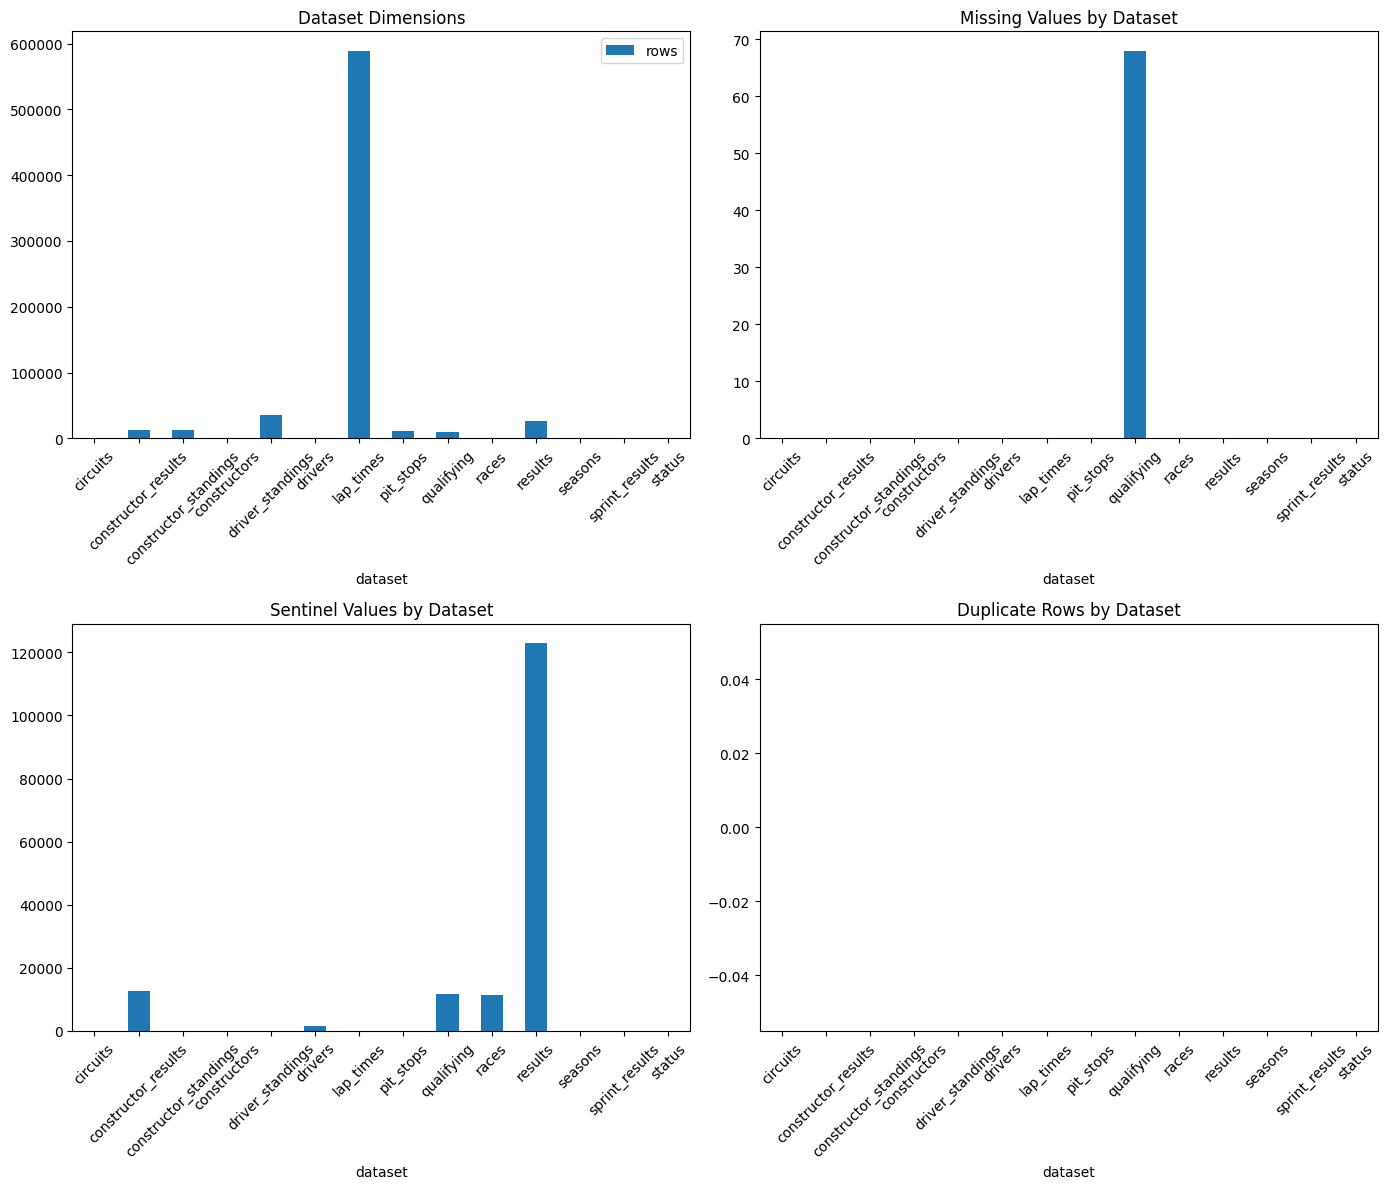

In [672]:
summary = []
missing = []
sentinels = []
duplicates = []

for name, df in tables.items():
    summary.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns)
    })
    
    missing.append({
        "dataset": name,
        "missing_values": df.isna().sum().sum()
    })
    
    sentinels.append({
        "dataset": name,
        "sentinel_values": (df == r"\N").sum().sum()
    })
    
    duplicates.append({
        "dataset": name,
        "duplicates": df.duplicated().sum()
    })


check = bool(tables['results'][['raceId', 'driverId']].duplicated().any())
number = tables['results'][['raceId', 'driverId']].duplicated().sum()
duplicate_groups = (
    tables['results'].groupby(["raceId", "driverId"])
    .size()
)
duplicate_groups = duplicate_groups[duplicate_groups > 1]

check_car_dupe = bool(tables['results'][['raceId', 'number']].duplicated().any())
number_car_dupe = tables['results'][['raceId', 'number']].duplicated().sum()
duplicate_cars_groups = (
    tables['results'].groupby(["raceId", "number"])
    .size()
)
duplicate_cars_groups = duplicate_cars_groups[duplicate_cars_groups > 1]

summary_df = pd.DataFrame(summary)
missing_df = pd.DataFrame(missing)
sentinels_df = pd.DataFrame(sentinels)
duplicates_df = pd.DataFrame(duplicates)

print('Does the results table contain any duplicate driver race data?: ', check)
print('How many? ', number)
print("Driver-race combinations with duplicates:", len(duplicate_groups))

print('\n')

print('Does the results table contain any duplicate car race data?: ', check_car_dupe)
print('How many? ', number_car_dupe)
print("Driver-car combinations with duplicates:", len(duplicate_cars_groups))

print('\n')

print('########### Missing Columns ####################')
for name, df in tables.items():
    missing_cols = df.isna().sum()
    missing_cols = missing_cols[missing_cols > 0]

    if len(missing_cols) > 0:
        print(f"\n{name}")
        print(missing_cols)

print('\n')

print('###################### Sentinel Columns ###################')
for name, df in tables.items():
    sentinel_cols = (df == r"\N").sum()
    sentinel_cols = sentinel_cols[sentinel_cols > 0]

    if len(sentinel_cols) > 0:
        print(f"\n{name}")
        print(sentinel_cols)

print('\n')

# Create a 2x2 grid of subplots with a shared figure size
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))

# 1. Dataset Dimensions (Top-Left)
summary_df.plot(
    x="dataset",
    y=["rows"],
    kind="bar",
    ax=axes[0, 0],
    title="Dataset Dimensions"
)

# 2. Missing Values (Top-Right)
missing_df.plot(
    x="dataset",
    y="missing_values",
    kind="bar",
    ax=axes[0, 1],
    title="Missing Values by Dataset",
    legend=False
)

# 3. Sentinel Values (Bottom-Left)
sentinels_df.plot(
    x="dataset",
    y="sentinel_values",
    kind="bar",
    ax=axes[1, 0],
    title="Sentinel Values by Dataset",
    legend=False
)

# 4. Duplicate Rows (Bottom-Right)
duplicates_df.plot(
    x="dataset",
    y="duplicates",
    kind="bar",
    ax=axes[1, 1],
    title="Duplicate Rows by Dataset",
    legend=False
)

# Rotate x-axis labels for readability and prevent overlapping titles/labels
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [673]:
for key, value in tables.items():
    print(f'###### {key} #######')
    print(value.info())
    print(value.describe())
    display(value.head(5))

###### circuits #######
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     str    
 2   name        77 non-null     str    
 3   location    77 non-null     str    
 4   country     77 non-null     str    
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     str    
dtypes: float64(2), int64(2), str(5)
memory usage: 5.5 KB
None
       circuitId        lat         lng          alt
count  77.000000  77.000000   77.000000    77.000000
mean   39.883117  33.442925    1.076683   247.012987
std    23.001701  22.808866   65.516951   362.738469
min     1.000000 -37.849700 -118.189000    -7.000000
25%    20.000000  32.777400   -9.394170    18.000000
50%    40.000000  40.951700    3.930830   129.000000


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


###### constructor_results #######
<class 'pandas.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  str    
dtypes: float64(1), int64(3), str(1)
memory usage: 493.3 KB
None
       constructorResultsId        raceId  constructorId        points
count          12625.000000  12625.000000   12625.000000  12625.000000
mean            8424.500594    528.235802      45.956119      4.053545
std             5666.310522    314.793555      59.468418      7.862202
min                1.000000      1.000000       1.000000      0.000000
25%             3157.000000    287.000000       6.000000      0.000000
50%             6313

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


###### constructor_standings #######
<class 'pandas.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  str    
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 732.4 KB
None
       constructorStandingsId        raceId  constructorId        points  \
count            13391.000000  13391.000000   13391.000000  13391.000000   
mean             16982.110821    535.399821      49.603390     37.178515   
std               8868.446172    307.705928      61.213953     84.346048   
min                 

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


###### constructors #######
<class 'pandas.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   constructorId   212 non-null    int64
 1   constructorRef  212 non-null    str  
 2   name            212 non-null    str  
 3   nationality     212 non-null    str  
 4   url             212 non-null    str  
dtypes: int64(1), str(4)
memory usage: 8.4 KB
None
       constructorId
count     212.000000
mean      107.547170
std        61.952685
min         1.000000
25%        54.750000
50%       107.500000
75%       160.250000
max       215.000000


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


###### driver_standings #######
<class 'pandas.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  str    
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 1.9 MB
None
       driverStandingsId        raceId      driverId        points  \
count       34863.000000  34863.000000  34863.000000  34863.000000   
mean        43176.154232    584.413562    316.932909     14.704423   
std         21934.276898    292.275820    274.665660     38.978094   
min             1.000000      1.000000      1.000000      0.000000   
25%         19834.500000  

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


###### drivers #######
<class 'pandas.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   driverId     861 non-null    int64
 1   driverRef    861 non-null    str  
 2   number       861 non-null    str  
 3   code         861 non-null    str  
 4   forename     861 non-null    str  
 5   surname      861 non-null    str  
 6   dob          861 non-null    str  
 7   nationality  861 non-null    str  
 8   url          861 non-null    str  
dtypes: int64(1), str(8)
memory usage: 60.7 KB
None
         driverId
count  861.000000
mean   431.061556
std    248.793797
min      1.000000
25%    216.000000
50%    431.000000
75%    646.000000
max    862.000000


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


###### lap_times #######
<class 'pandas.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   raceId        589081 non-null  int64
 1   driverId      589081 non-null  int64
 2   lap           589081 non-null  int64
 3   position      589081 non-null  int64
 4   time          589081 non-null  str  
 5   milliseconds  589081 non-null  int64
dtypes: int64(5), str(1)
memory usage: 27.0 MB
None
              raceId       driverId            lap       position  \
count  589081.000000  589081.000000  589081.000000  589081.000000   
mean      600.544465     325.796446      30.018104       9.661951   
std       434.375976     387.561736      18.407126       5.528553   
min         1.000000       1.000000       1.000000       1.000000   
25%       140.000000      16.000000      14.000000       5.000000   
50%       861.000000      48.000000      29.000000       9.000000   
75%  

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


###### pit_stops #######
<class 'pandas.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   raceId        11371 non-null  int64
 1   driverId      11371 non-null  int64
 2   stop          11371 non-null  int64
 3   lap           11371 non-null  int64
 4   time          11371 non-null  str  
 5   duration      11371 non-null  str  
 6   milliseconds  11371 non-null  int64
dtypes: int64(5), str(2)
memory usage: 622.0 KB
None
             raceId      driverId          stop           lap  milliseconds
count  11371.000000  11371.000000  11371.000000  11371.000000  1.137100e+04
mean     981.194882    549.734500      1.787969     25.387389  8.523050e+04
std       92.326831    383.734981      1.521462     14.831497  3.104273e+05
min      841.000000      1.000000      1.000000      1.000000  1.289700e+04
25%      895.000000     20.000000      1.000000     13.000000  2.193750e+04


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


###### qualifying #######
<class 'pandas.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   qualifyId      10494 non-null  int64
 1   raceId         10494 non-null  int64
 2   driverId       10494 non-null  int64
 3   constructorId  10494 non-null  int64
 4   number         10494 non-null  int64
 5   position       10494 non-null  int64
 6   q1             10494 non-null  str  
 7   q2             10472 non-null  str  
 8   q3             10448 non-null  str  
dtypes: int64(6), str(3)
memory usage: 738.0 KB
None
          qualifyId        raceId      driverId  constructorId        number  \
count  10494.000000  10494.000000  10494.000000   10494.000000  10494.000000   
mean    5262.482847    624.600915    343.002287      47.918430     18.786449   
std     3046.588486    428.298147    389.586448      73.217993     18.447502   
min        1.000000      1.000000      1.0

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


###### races #######
<class 'pandas.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   raceId       1125 non-null   int64
 1   year         1125 non-null   int64
 2   round        1125 non-null   int64
 3   circuitId    1125 non-null   int64
 4   name         1125 non-null   str  
 5   date         1125 non-null   str  
 6   time         1125 non-null   str  
 7   url          1125 non-null   str  
 8   fp1_date     1125 non-null   str  
 9   fp1_time     1125 non-null   str  
 10  fp2_date     1125 non-null   str  
 11  fp2_time     1125 non-null   str  
 12  fp3_date     1125 non-null   str  
 13  fp3_time     1125 non-null   str  
 14  quali_date   1125 non-null   str  
 15  quali_time   1125 non-null   str  
 16  sprint_date  1125 non-null   str  
 17  sprint_time  1125 non-null   str  
dtypes: int64(4), str(14)
memory usage: 158.3 KB
None
            raceId         ye

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


###### results #######
<class 'pandas.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  str    
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  str    
 7   positionText     26759 non-null  str    
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  str    
 12  milliseconds     26759 non-null  str    
 13  fastestLap       26759 non-null  str    
 14  rank             26759 non-null  str    
 15  fastestLapTime   26759 non-null  str    
 16  fastestLapSpeed  26759 non-null  str    
 17  

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


###### seasons #######
<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   year    75 non-null     int64
 1   url     75 non-null     str  
dtypes: int64(1), str(1)
memory usage: 1.3 KB
None
              year
count    75.000000
mean   1987.000000
std      21.794495
min    1950.000000
25%    1968.500000
50%    1987.000000
75%    2005.500000
max    2024.000000


,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


###### sprint_results #######
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   resultId        360 non-null    int64
 1   raceId          360 non-null    int64
 2   driverId        360 non-null    int64
 3   constructorId   360 non-null    int64
 4   number          360 non-null    int64
 5   grid            360 non-null    int64
 6   position        360 non-null    str  
 7   positionText    360 non-null    str  
 8   positionOrder   360 non-null    int64
 9   points          360 non-null    int64
 10  laps            360 non-null    int64
 11  time            360 non-null    str  
 12  milliseconds    360 non-null    str  
 13  fastestLap      360 non-null    str  
 14  fastestLapTime  360 non-null    str  
 15  statusId        360 non-null    int64
dtypes: int64(10), str(6)
memory usage: 45.1 KB
None
         resultId       raceId    driverId  const

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


###### status #######
<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   statusId  139 non-null    int64
 1   status    139 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.3 KB
None
         statusId
count  139.000000
mean    71.237410
std     41.092434
min      1.000000
25%     35.500000
50%     72.000000
75%    106.500000
max    141.000000


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


## **String Normalization**

In [674]:
for column in df.columns:
    if(df[column].dtype == object):
        df[column] = df[column].str.strip()
        df[column] = df[column].replace(r'^\s*$', np.nan, regex=True)

## **Numerical Columns Casting**

In [675]:
cleaned_tables = {}

def convert_column_to_number(table):
    for column in table.columns:
        new_column = pd.to_numeric(table[column], errors='coerce')
        if new_column.notna().sum() == table[column].notna().sum():
            table[column] = new_column
    return table

# Convert Number Columns To Number Type After Removing \N 
for table_name,table in tables.items():
    cleaned_tables[table_name] = convert_column_to_number(table.replace("\\N", np.nan))

In [676]:
for key, value in cleaned_tables.items():
    print(f'###### {key} #######')
    print(value.info())
    display(value.head(5))

###### circuits #######
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     str    
 2   name        77 non-null     str    
 3   location    77 non-null     str    
 4   country     77 non-null     str    
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     str    
dtypes: float64(2), int64(2), str(5)
memory usage: 5.5 KB
None


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


###### constructor_results #######
<class 'pandas.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     str    
dtypes: float64(1), int64(3), str(1)
memory usage: 493.3 KB
None


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


###### constructor_standings #######
<class 'pandas.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  str    
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 732.4 KB
None


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


###### constructors #######
<class 'pandas.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   constructorId   212 non-null    int64
 1   constructorRef  212 non-null    str  
 2   name            212 non-null    str  
 3   nationality     212 non-null    str  
 4   url             212 non-null    str  
dtypes: int64(1), str(4)
memory usage: 8.4 KB
None


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


###### driver_standings #######
<class 'pandas.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  str    
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 1.9 MB
None


,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


###### drivers #######
<class 'pandas.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   driverId     861 non-null    int64  
 1   driverRef    861 non-null    str    
 2   number       59 non-null     float64
 3   code         104 non-null    str    
 4   forename     861 non-null    str    
 5   surname      861 non-null    str    
 6   dob          861 non-null    str    
 7   nationality  861 non-null    str    
 8   url          861 non-null    str    
dtypes: float64(1), int64(1), str(7)
memory usage: 60.7 KB
None


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


###### lap_times #######
<class 'pandas.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   raceId        589081 non-null  int64
 1   driverId      589081 non-null  int64
 2   lap           589081 non-null  int64
 3   position      589081 non-null  int64
 4   time          589081 non-null  str  
 5   milliseconds  589081 non-null  int64
dtypes: int64(5), str(1)
memory usage: 27.0 MB
None


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


###### pit_stops #######
<class 'pandas.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   raceId        11371 non-null  int64
 1   driverId      11371 non-null  int64
 2   stop          11371 non-null  int64
 3   lap           11371 non-null  int64
 4   time          11371 non-null  str  
 5   duration      11371 non-null  str  
 6   milliseconds  11371 non-null  int64
dtypes: int64(5), str(2)
memory usage: 622.0 KB
None


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


###### qualifying #######
<class 'pandas.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   qualifyId      10494 non-null  int64
 1   raceId         10494 non-null  int64
 2   driverId       10494 non-null  int64
 3   constructorId  10494 non-null  int64
 4   number         10494 non-null  int64
 5   position       10494 non-null  int64
 6   q1             10338 non-null  str  
 7   q2             5847 non-null   str  
 8   q3             3629 non-null   str  
dtypes: int64(6), str(3)
memory usage: 738.0 KB
None


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


###### races #######
<class 'pandas.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   raceId       1125 non-null   int64
 1   year         1125 non-null   int64
 2   round        1125 non-null   int64
 3   circuitId    1125 non-null   int64
 4   name         1125 non-null   str  
 5   date         1125 non-null   str  
 6   time         394 non-null    str  
 7   url          1125 non-null   str  
 8   fp1_date     90 non-null     str  
 9   fp1_time     68 non-null     str  
 10  fp2_date     90 non-null     str  
 11  fp2_time     68 non-null     str  
 12  fp3_date     72 non-null     str  
 13  fp3_time     53 non-null     str  
 14  quali_date   90 non-null     str  
 15  quali_time   68 non-null     str  
 16  sprint_date  18 non-null     str  
 17  sprint_time  15 non-null     str  
dtypes: int64(4), str(14)
memory usage: 158.3 KB
None


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


###### results #######
<class 'pandas.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  str    
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   str    
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   str    
 16  fastestLapSpeed  8252 non-null   float64
 17  

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


###### seasons #######
<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   year    75 non-null     int64
 1   url     75 non-null     str  
dtypes: int64(1), str(1)
memory usage: 1.3 KB
None


,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


###### sprint_results #######
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    str    
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    str    
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    str    
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), str(3)
memory usage: 45.1 KB
None


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


###### status #######
<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   statusId  139 non-null    int64
 1   status    139 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.3 KB
None


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


## **Date Columns Casting**

In [677]:
# Convert Date Strings To Date Objects
cleaned_tables['races']['date'] = pd.to_datetime(cleaned_tables['races']['date'])
cleaned_tables['drivers']['dob'] = pd.to_datetime(cleaned_tables['drivers']['dob'])

## **Lap Times to Seconds Normalization**

In [678]:
# Convert Lap Times To Seconds
def time_to_seconds(text):
    if pd.isna(text):
        return np.nan
    minutes, seconds = text.split(':')
    return float(minutes) * 60 + float(seconds)


for col in ['q1', 'q2', 'q3']:
    cleaned_tables['qualifying'][col] = cleaned_tables['qualifying'][col].map(time_to_seconds)

In [679]:
cleaned_tables['qualifying'].head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,86.572,85.187,86.714
1,2,18,9,2,4,2,86.103,85.315,86.869
2,3,18,5,1,23,3,85.664,85.452,87.079
3,4,18,13,6,2,4,85.994,85.691,87.178
4,5,18,2,2,3,5,85.960,85.518,87.236


## **Referential Integrity**

In [680]:
# Create Composite Primary Keys
cleaned_tables['lap_times']['lapId'] = (cleaned_tables['lap_times']['raceId'].astype(str) + '_' + cleaned_tables['lap_times']['driverId'].astype(str) + '_' + cleaned_tables['lap_times']['lap'].astype(str))
cleaned_tables['pit_stops']['stopId'] = (cleaned_tables['pit_stops']['raceId'].astype(str) + '_' + cleaned_tables['pit_stops']['driverId'].astype(str) + '_' + cleaned_tables['pit_stops']['stop'].astype(str))

primary_keys = {
    'circuits': 'circuitId', 
    'constructor_results': 'constructorResultsId', 
    'constructor_standings': 'constructorStandingsId',
    'constructors': 'constructorId', 
    'driver_standings': 'driverStandingsId', 
    'drivers': 'driverId',
    'lap_times': 'lapId',
    'pit_stops': 'stopId',
    'qualifying': 'qualifyId', 
    'races': 'raceId',
    'results': 'resultId', 
    'seasons': 'year',
    'sprint_results': 'resultId',
    'status': 'statusId', 
}


for table_name, key in primary_keys.items():
    unique = cleaned_tables[table_name][key].is_unique
    no_missing = cleaned_tables[table_name][key].notna().all()
    print(f'{table_name}.{key}: \n unique = {unique} \n no missing = {no_missing}')

circuits.circuitId: 
 unique = True 
 no missing = True
constructor_results.constructorResultsId: 
 unique = True 
 no missing = True
constructor_standings.constructorStandingsId: 
 unique = True 
 no missing = True
constructors.constructorId: 
 unique = True 
 no missing = True
driver_standings.driverStandingsId: 
 unique = True 
 no missing = True
drivers.driverId: 
 unique = True 
 no missing = True
lap_times.lapId: 
 unique = True 
 no missing = True
pit_stops.stopId: 
 unique = True 
 no missing = True
qualifying.qualifyId: 
 unique = True 
 no missing = True
races.raceId: 
 unique = True 
 no missing = True
results.resultId: 
 unique = True 
 no missing = True
seasons.year: 
 unique = True 
 no missing = True
sprint_results.resultId: 
 unique = True 
 no missing = True
status.statusId: 
 unique = True 
 no missing = True


In [681]:
foreign_keys = [
    
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),

    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),

    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),

    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),

    
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),

    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),

    ('races', 'circuitId', 'circuits', 'circuitId'),

    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'statusId', 'status', 'statusId'),


    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
    
]

for table, column, parent, parent_key in foreign_keys:
    # ~ means 'not'
    missing = ~ cleaned_tables[table][column].isin(cleaned_tables[parent][parent_key])
    print(f'{table}.{column} -> {parent}: {missing.sum()} values not found')

constructor_results.raceId -> races: 0 values not found
constructor_results.constructorId -> constructors: 0 values not found
constructor_standings.raceId -> races: 0 values not found
constructor_standings.constructorId -> constructors: 0 values not found
driver_standings.raceId -> races: 0 values not found
driver_standings.driverId -> drivers: 0 values not found
lap_times.raceId -> races: 0 values not found
lap_times.driverId -> drivers: 0 values not found
pit_stops.raceId -> races: 0 values not found
pit_stops.driverId -> drivers: 0 values not found
qualifying.raceId -> races: 0 values not found
qualifying.driverId -> drivers: 0 values not found
qualifying.constructorId -> constructors: 0 values not found
races.circuitId -> circuits: 0 values not found
results.raceId -> races: 0 values not found
results.driverId -> drivers: 0 values not found
results.constructorId -> constructors: 0 values not found
results.statusId -> status: 0 values not found
sprint_results.raceId -> races: 0 valu

## **Shared Drive Handling**

### **1 Driver 2 Cars**

In [682]:
# all duplicates
temporary_results = cleaned_tables['results']
duplicates = (
    temporary_results[
        temporary_results.duplicated(
            ['raceId', 'driverId'],
            keep=False
        )
    ]
    .sort_values(['raceId', 'driverId', 'positionOrder'])
)
duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
17362,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17740,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20142,20143,838,627,154,20.0,6,NaN,R,12,0.0,10,NaN,NaN,NaN,NaN,NaN,NaN,25
20183,20184,839,579,51,60.0,7,NaN,R,13,0.0,34,NaN,NaN,NaN,NaN,NaN,NaN,5
20163,20164,839,579,51,18.0,1,NaN,R,15,1.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6
20182,20183,839,647,6,48.0,6,2.0,2,2,3.0,80,NaN,NaN,NaN,NaN,NaN,NaN,1


In [683]:
# we chose to keep best position order as it is the entry most likely to finish the race 
sorted_results = temporary_results.sort_values(
    ['raceId', 'driverId', 'positionOrder']
)

filtered_duplicates = sorted_results[
    sorted_results.duplicated(
        ['raceId', 'driverId'],
        keep='first'
    )
]

filtered_duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17743,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
17963,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23
18062,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19997,19998,831,642,51,34.0,2,NaN,R,16,0.0,6,NaN,NaN,NaN,NaN,NaN,NaN,5
20096,20097,835,529,150,14.0,8,NaN,R,31,0.0,30,NaN,NaN,NaN,NaN,NaN,NaN,67
20142,20143,838,627,154,20.0,6,NaN,R,12,0.0,10,NaN,NaN,NaN,NaN,NaN,NaN,25
20163,20164,839,579,51,18.0,1,NaN,R,15,1.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6


In [684]:
cleaned_tables['results'] = temporary_results.drop(
    filtered_duplicates.index
)

cleaned_tables['results']

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26754,26760,1144,825,210,20.0,14,16.0,16,16,0.0,57,NaN,NaN,57.0,1.0,1:25.637,222.002,11
26755,26761,1144,859,215,30.0,12,17.0,17,17,0.0,55,NaN,NaN,52.0,12.0,1:28.751,214.212,5
26756,26762,1144,822,15,77.0,9,NaN,R,18,0.0,30,NaN,NaN,14.0,19.0,1:29.482,212.462,130
26757,26763,1144,861,3,43.0,20,NaN,R,19,0.0,26,NaN,NaN,5.0,17.0,1:29.411,212.631,5


### **1 Car 2 Drivers**

In [685]:
# all duplicates
temporary_results = cleaned_tables['results']
duplicates = (
    temporary_results[
        temporary_results.duplicated(
            ['raceId', 'number'],
            keep=False
        )
    ]
    .sort_values(['raceId', 'number', 'positionOrder'])
)
duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
11576,11577,484,176,57,14.0,18,4.0,4,4,3.0,62,+1:17.03,7300690.0,NaN,NaN,NaN,NaN,1
11602,11603,484,218,57,14.0,0,NaN,W,30,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12290,12291,508,191,21,30.0,0,NaN,F,27,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
12292,12293,508,200,21,30.0,0,NaN,W,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12725,12726,525,217,182,5.0,17,7.0,7,7,0.0,68,NaN,NaN,NaN,NaN,NaN,NaN,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20181,20182,838,627,154,26.0,15,6.0,6,6,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,18
20150,20151,839,802,6,48.0,6,2.0,2,2,3.0,80,+1:18.6,10356000.0,NaN,NaN,NaN,NaN,1
20182,20183,839,647,6,48.0,6,2.0,2,2,3.0,80,NaN,NaN,NaN,NaN,NaN,NaN,1
20161,20162,839,641,51,60.0,7,NaN,R,13,0.0,34,NaN,NaN,NaN,NaN,NaN,NaN,5


In [686]:
# we chose to keep best position order as it is the entry most likely to finish the race 
sorted_results = temporary_results.sort_values(
    ['raceId', 'number', 'positionOrder']
)

filtered_duplicates = sorted_results[
    sorted_results.duplicated(
        ['raceId', 'number'],
        keep='first'
    )
]

filtered_duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
11602,11603,484,218,57,14.0,0,NaN,W,30,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12292,12293,508,200,21,30.0,0,NaN,W,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12748,12749,525,182,182,5.0,0,NaN,W,30,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
13392,13393,548,223,57,22.0,0,NaN,F,24,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13485,13486,551,175,63,18.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20179,20180,835,803,161,24.0,17,NaN,R,27,0.0,108,NaN,NaN,NaN,NaN,NaN,NaN,51
20180,20181,838,774,154,16.0,4,5.0,5,5,1.0,59,NaN,NaN,NaN,NaN,NaN,NaN,15
20181,20182,838,627,154,26.0,15,6.0,6,6,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,18
20182,20183,839,647,6,48.0,6,2.0,2,2,3.0,80,NaN,NaN,NaN,NaN,NaN,NaN,1


In [687]:
cleaned_tables['results'] = temporary_results.drop(
    filtered_duplicates.index
)

cleaned_tables['results']

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26754,26760,1144,825,210,20.0,14,16.0,16,16,0.0,57,NaN,NaN,57.0,1.0,1:25.637,222.002,11
26755,26761,1144,859,215,30.0,12,17.0,17,17,0.0,55,NaN,NaN,52.0,12.0,1:28.751,214.212,5
26756,26762,1144,822,15,77.0,9,NaN,R,18,0.0,30,NaN,NaN,14.0,19.0,1:29.482,212.462,130
26757,26763,1144,861,3,43.0,20,NaN,R,19,0.0,26,NaN,NaN,5.0,17.0,1:29.411,212.631,5


## **Post Cleaning EDA**

Does the results table contain any duplicate race data?:  False
How many?  0
Driver-race combinations with duplicates: 0


Does the results table contain any duplicate car race data?:  False
How many?  0
Driver-car combinations with duplicates: 0



########### Missing Columns ####################

constructor_results
status    12608
dtype: int64

drivers
number    802
code      757
dtype: int64

qualifying
q1     156
q2    4647
q3    6865
dtype: int64

races
time            731
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64

results
number                 3
position           10808
time               18874
milliseconds       18874
fastestLap         18279
rank               18021
fastestLapTime     18279
fastestLapSpeed    18279
dtype: int64

sprint_results
position          15
time              20
milliseconds      20
fa

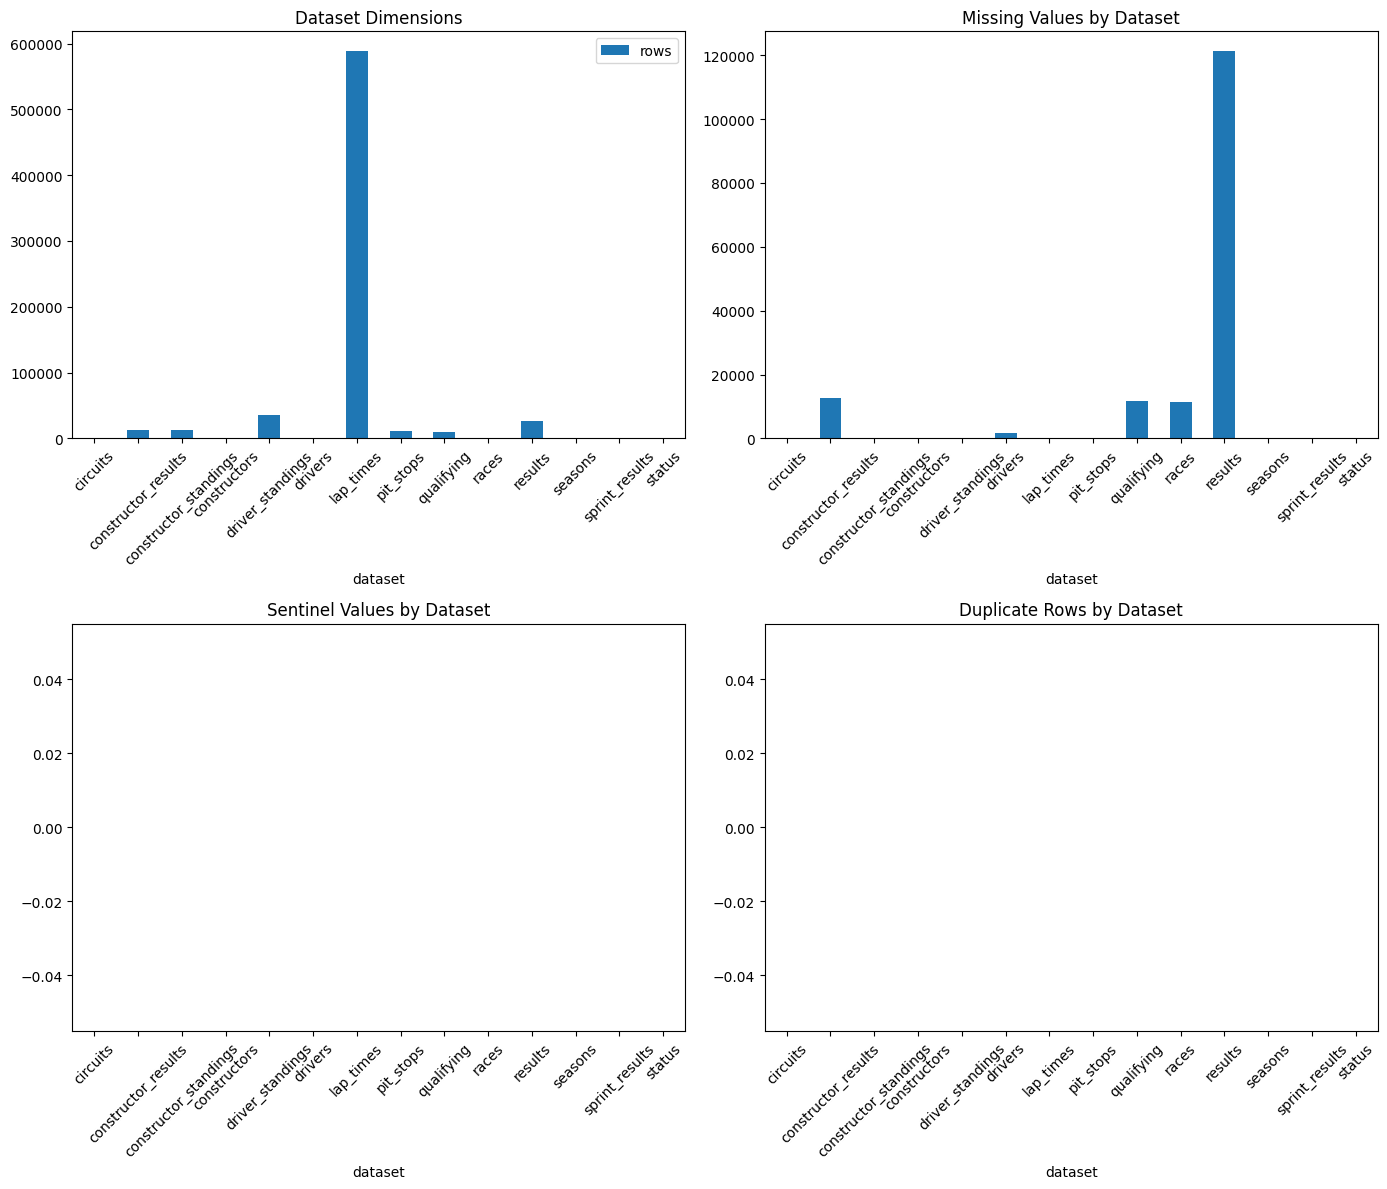

In [688]:
summary = []
missing = []
sentinels = []
duplicates = []

for name, df in cleaned_tables.items():
    summary.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns)
    })

    missing.append({
        "dataset": name,
        "missing_values": df.isna().sum().sum()
    })

    sentinels.append({
        "dataset": name,
        "sentinel_values": (df == r"\N").sum().sum()
    })

    duplicates.append({
        "dataset": name,
        "duplicates": df.duplicated().sum()
    })


check = cleaned_tables['results'][['raceId', 'driverId']].duplicated().any()
number = cleaned_tables['results'][['raceId', 'driverId']].duplicated().sum()
duplicate_groups = (
    cleaned_tables['results'].groupby(["raceId", "driverId"])
    .size()
)
duplicate_groups = duplicate_groups[duplicate_groups > 1]

check_car_dupe = bool(cleaned_tables['results'][['raceId', 'number']].duplicated().any())
number_car_dupe = cleaned_tables['results'][['raceId', 'number']].duplicated().sum()
duplicate_cars_groups = (
    cleaned_tables['results'].groupby(["raceId", "number"])
    .size()
)
duplicate_cars_groups = duplicate_cars_groups[duplicate_cars_groups > 1]

summary_df = pd.DataFrame(summary)
missing_df = pd.DataFrame(missing)
sentinels_df = pd.DataFrame(sentinels)
duplicates_df = pd.DataFrame(duplicates)


print('Does the results table contain any duplicate race data?: ', check)
print('How many? ', number)
print("Driver-race combinations with duplicates:", len(duplicate_groups))

print('\n')

print('Does the results table contain any duplicate car race data?: ', check_car_dupe)
print('How many? ', number_car_dupe)
print("Driver-car combinations with duplicates:", len(duplicate_cars_groups))

print('\n')

print('')
print('########### Missing Columns ####################')
for name, df in cleaned_tables.items():
    missing_cols = df.isna().sum()
    missing_cols = missing_cols[missing_cols > 0]

    if len(missing_cols) > 0:
        print(f"\n{name}")
        print(missing_cols)

print("")
print('###################### Sentinel Columns ###################')
for name, df in cleaned_tables.items():
    sentinel_cols = (df == r"\N").sum()
    sentinel_cols = sentinel_cols[sentinel_cols > 0]

    if len(sentinel_cols) > 0:
        print(f"\n{name}")
        print(sentinel_cols)


# Create a 2x2 grid of subplots with a shared figure size
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))

# 1. Dataset Dimensions (Top-Left)
summary_df.plot(
    x="dataset",
    y=["rows"],
    kind="bar",
    ax=axes[0, 0],
    title="Dataset Dimensions"
)

# 2. Missing Values (Top-Right)
missing_df.plot(
    x="dataset",
    y="missing_values",
    kind="bar",
    ax=axes[0, 1],
    title="Missing Values by Dataset",
    legend=False
)

# 3. Sentinel Values (Bottom-Left)
sentinels_df.plot(
    x="dataset",
    y="sentinel_values",
    kind="bar",
    ax=axes[1, 0],
    title="Sentinel Values by Dataset",
    legend=False
)

# 4. Duplicate Rows (Bottom-Right)
duplicates_df.plot(
    x="dataset",
    y="duplicates",
    kind="bar",
    ax=axes[1, 1],
    title="Duplicate Rows by Dataset",
    legend=False
)

# Rotate x-axis labels for readability and prevent overlapping titles/labels
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [689]:
# for name, table in cleaned_tables.items():
#     print(f"=========== {name} ===========")
#     display(table.head(1))

display(cleaned_tables['races'].head(1))
display(cleaned_tables['circuits'].head(1))
display(cleaned_tables['results'].head(1))
display(cleaned_tables['drivers'].head(1))
display(cleaned_tables['constructor_standings'].head(1))

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.3,1


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1


# **Data Engineering Questions**

## **Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era? Distinguish qualifying position from grid (which can differ due to penalties).**

In [690]:
mask = (cleaned_tables['results']['grid'] <= 2) & (cleaned_tables['results']['position'] <= 3)

merged_before_2014 = (
    cleaned_tables['results'][mask]
    .merge(cleaned_tables['races'][cleaned_tables['races']['year'] < 2014][['raceId', 'circuitId']], on='raceId')
    .merge(cleaned_tables['circuits'][['circuitId', 'name']], on='circuitId')
)

merged_after_2014 = (
    cleaned_tables['results'][mask]
    .merge(cleaned_tables['races'][cleaned_tables['races']['year'] >= 2014][['raceId', 'circuitId']], on='raceId')
    .merge(cleaned_tables['circuits'][['circuitId', 'name']], on='circuitId')
)

df_before_2014 = (
    merged_before_2014.groupby('name')
    .size()
    .sort_values(ascending=False)
    .rename('num')
    .reset_index()
    .rename(columns={'name': 'circuit'})
)



df_after_2014 = (
    merged_after_2014.groupby('name')
    .size()
    .sort_values(ascending=False)
    .rename('num')
    .reset_index()
    .rename(columns={'name': 'circuit'})
)

print(f"=====================================================")
print(f"BEFORE 2014")
display(df_before_2014)
print(f"=====================================================")
print(f"=====================================================")
print(f"AFTER 2014")
display(df_after_2014)
print(f"=====================================================")

BEFORE 2014


,circuit,num
0,Autodromo Nazionale di Monza,60
1,Circuit de Monaco,59
2,Silverstone Circuit,53
3,Circuit de Spa-Francorchamps,49
4,Nürburgring,45
...,...,...
62,Le Mans,1
63,Monsanto Park Circuit,1
64,Montjuïc,1
65,Las Vegas Street Circuit,1


AFTER 2014


,circuit,num
0,Red Bull Ring,19
1,Yas Marina Circuit,19
2,Circuit de Barcelona-Catalunya,18
3,Circuit de Spa-Francorchamps,18
4,Silverstone Circuit,18
5,Circuit de Monaco,17
6,Circuit of the Americas,16
7,Autodromo Nazionale di Monza,16
8,Suzuka Circuit,16
9,Bahrain International Circuit,16


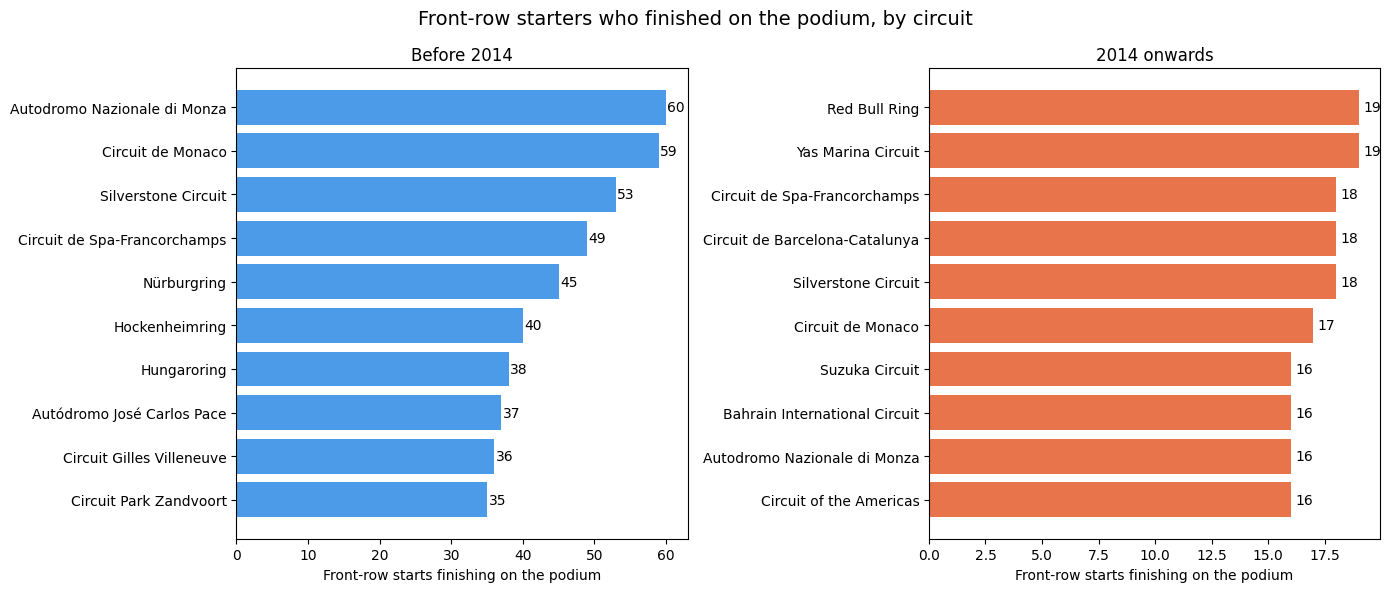

In [691]:
top = 10
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, df, title, color in [
    (axes[0], df_before_2014, 'Before 2014', '#4c9be8'),
    (axes[1], df_after_2014,  '2014 onwards', '#e8744c'),
]:
    data = df.head(top).sort_values('num')   # sort so the biggest bar ends up on top
    ax.barh(data['circuit'], data['num'], color=color)
    ax.set_title(title)
    ax.set_xlabel('Front-row starts finishing on the podium')
    for i, v in enumerate(data['num']):
        ax.text(v + 0.2, i, str(v), va='center')   # value labels

fig.suptitle('Front-row starters who finished on the podium, by circuit', fontsize=14)
plt.tight_layout()
plt.show()

## **Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting position (i.e., comparing drivers who started from similar grid positions, so the effect isn’t just because home drivers happen to qualify better)?**

In [692]:
nat_to_country = {
    'American': 'USA',
    'American-Italian': 'USA',
    'Argentine': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Argentinian ': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'East Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela',
}


df = (
    cleaned_tables['results'][['raceId','position','grid','driverId']]
    .merge(cleaned_tables['races'][['raceId','circuitId']] , on='raceId')
    .merge(cleaned_tables['drivers'][['driverId','nationality']], on='driverId')
    .merge(cleaned_tables['circuits'][['circuitId','country']], on='circuitId')
)

df['driver_country'] = df['nationality'].map(nat_to_country)

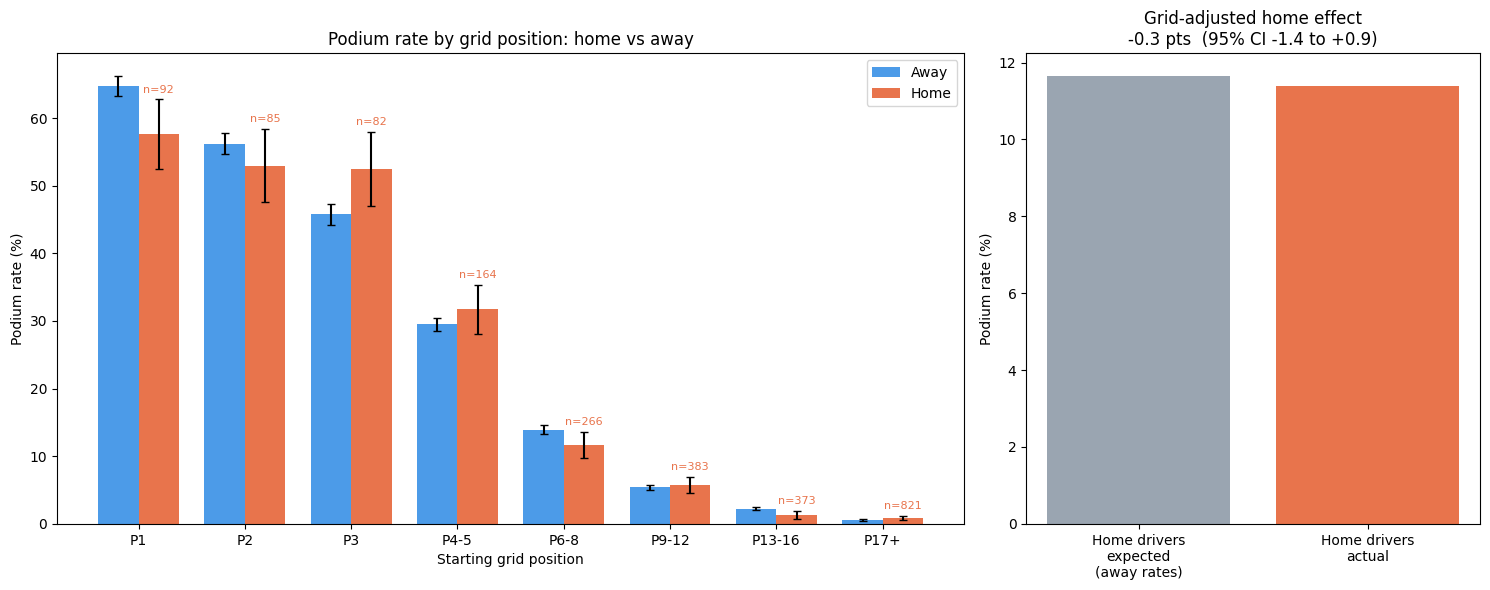

In [693]:
d = df.copy()
d = d[d['grid'] >= 1]                                  # drop pit-lane starts (grid == 0)
d['home']   = d['driver_country'] == d['country']
d['podium'] = (d['position'] <= 3)                     # NaN (DNF) -> False

bins   = [0, 1, 2, 3, 5, 8, 12, 16, 40]
labels = ['P1', 'P2', 'P3', 'P4-5', 'P6-8', 'P9-12', 'P13-16', 'P17+']
d['grid_bin'] = pd.cut(d['grid'], bins=bins, labels=labels)

# podium rate per grid bin, split by home/away
g = (d.groupby(['grid_bin', 'home'], observed=True)['podium']
       .agg(rate='mean', k='sum', n='size')
       .unstack('home'))

# standard error for error bars
def se(rate, n): return np.sqrt(rate * (1 - rate) / n)

# grid-adjusted effect: actual home podium rate vs the rate home drivers
# would have had if they converted like away drivers from the same grid bin
def adjusted_effect(data):
    t = data.groupby(['grid_bin', 'home'], observed=True)['podium'].agg(['mean', 'size']).unstack('home')
    t = t.dropna()
    w = t[('size', True)]
    expected = (t[('mean', False)] * w).sum() / w.sum()
    actual   = (t[('mean', True)]  * w).sum() / w.sum()
    return actual, expected

actual, expected = adjusted_effect(d)

# bootstrap CI for (actual - expected)
rng = np.random.default_rng(0)
boots = []
for _ in range(500):
    s = d.sample(len(d), replace=True, random_state=int(rng.integers(1e9)))
    a, e = adjusted_effect(s)
    boots.append(a - e)
lo, hi = np.percentile(boots, [2.5, 97.5])

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1]})

x = np.arange(len(g))
wd = 0.38
away_rate, home_rate = g[('rate', False)] * 100, g[('rate', True)] * 100
away_err = se(g[('rate', False)], g[('n', False)]) * 100
home_err = se(g[('rate', True)],  g[('n', True)])  * 100

ax1.bar(x - wd/2, away_rate, wd, yerr=away_err, color='#4c9be8', label='Away', capsize=3)
ax1.bar(x + wd/2, home_rate, wd, yerr=home_err, color='#e8744c', label='Home', capsize=3)
for i, (_, r) in enumerate(g.iterrows()):
    ax1.text(i + wd/2, home_rate.iloc[i] + home_err.iloc[i] + 1, f"n={int(r[('n', True)])}",
             ha='center', fontsize=8, color='#e8744c')
ax1.set_xticks(x)
ax1.set_xticklabels(g.index)
ax1.set_xlabel('Starting grid position')
ax1.set_ylabel('Podium rate (%)')
ax1.set_title('Podium rate by grid position: home vs away')
ax1.legend()

ax2.bar(['Home drivers\nexpected\n(away rates)', 'Home drivers\nactual'],
        [expected * 100, actual * 100], color=['#9aa5b1', '#e8744c'])
ax2.set_ylabel('Podium rate (%)')
ax2.set_title(f'Grid-adjusted home effect\n{(actual-expected)*100:+.1f} pts  (95% CI {lo*100:+.1f} to {hi*100:+.1f})')

plt.tight_layout()
plt.show()

## **Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?**

In [694]:
df = cleaned_tables['results'][['raceId', 'statusId','constructorId']].merge(cleaned_tables['status'], on='statusId').merge(cleaned_tables['constructors'][['constructorId', 'name']], on='constructorId').merge(cleaned_tables['races'][['raceId', 'year']], on='raceId')

mechanical_failures = ['Engine', 'Gearbox', 'Hydraulics']

all_races_by_constructor = df[df['status'].isin(mechanical_failures)]

r_2014_2021 = all_races_by_constructor[all_races_by_constructor['year'].between(2014, 2021)]
r_2022_2024 = all_races_by_constructor[all_races_by_constructor['year'].between(2022, 2024)]

# r_2014_2021.groupby('name')

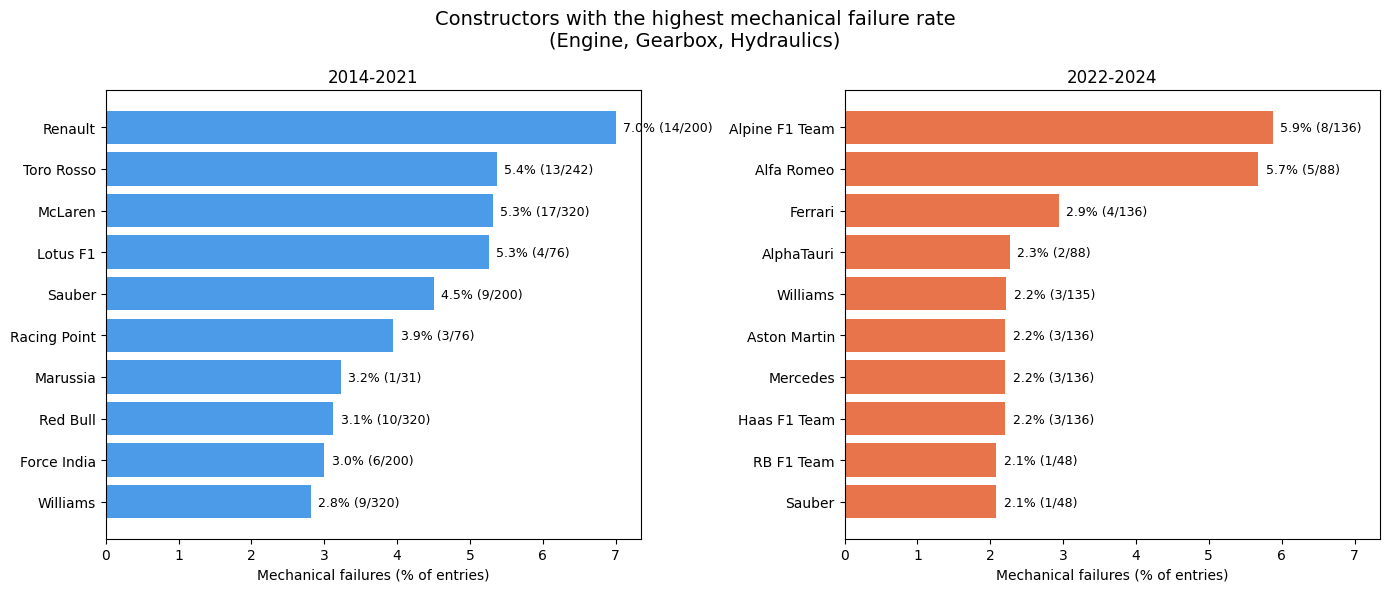

In [695]:
def failure_summary(df, start, end, min_entries=20):
    d = df[df['year'].between(start, end)]
    g = d.groupby('name').agg(
        entries=('raceId', 'size'),
        failures=('status', lambda s: s.isin(mechanical_failures).sum()),
    )
    g['rate'] = g['failures'] / g['entries'] * 100
    return g[g['entries'] >= min_entries]   # drop constructors with tiny samples

periods = [(2014, 2021, '#4c9be8'), (2022, 2024, '#e8744c')]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

for ax, (start, end, color) in zip(axes, periods):
    s = failure_summary(df, start, end).nlargest(10, 'rate').sort_values('rate')
    ax.barh(s.index, s['rate'], color=color)
    for i, (rate, n, f) in enumerate(zip(s['rate'], s['entries'], s['failures'])):
        ax.text(rate + 0.1, i, f'{rate:.1f}% ({f}/{n})', va='center', fontsize=9)
    ax.set_title(f'{start}-{end}')
    ax.set_xlabel('Mechanical failures (% of entries)')

fig.suptitle('Constructors with the highest mechanical failure rate\n(Engine, Gearbox, Hydraulics)', fontsize=14)
plt.tight_layout()
plt.show()

# **Feature Selection & Engineering**

In [696]:
def add_pre_race_driver_standings(modeling_data, driver_standings, races):
    """
    Add current-season pre-race points/wins and previous-season
    final points/wins for each driver.

    Current-season features use the latest standings record from
    an earlier round in the same season. If no earlier record
    exists, they default to zero.

    Previous-season features use the driver's final standings
    record from the immediately preceding season, or zero if
    unavailable.
    """

    race_order = races[['raceId', 'year', 'round']].copy()

    standings = (
        driver_standings[['raceId', 'driverId', 'points', 'wins']]
        .merge(
            race_order,
            on='raceId',
            how='left',
            validate='many_to_one'
        )
    )

    data = modeling_data.copy().reset_index(drop=True)
    data['_row_id'] = range(len(data))

    # Attach each driver's standings records from the same season.
    candidates = data[
        ['_row_id', 'driverId', 'year', 'round']
    ].merge(
        standings,
        on=['driverId', 'year'],
        how='left',
        suffixes=('', '_standing')
    )

    # Only records from earlier rounds are eligible.
    candidates = candidates[
        candidates['round_standing'] < candidates['round']
    ]

    # Latest standings record before the target race.
    current_season = (
        candidates
        .sort_values(
            ['_row_id', 'round_standing', 'raceId']
        )
        .drop_duplicates('_row_id', keep='last')
        [
            ['_row_id', 'points', 'wins']
        ]
        .rename(columns={
            'points': 'driver_points_before_race',
            'wins': 'driver_wins_before_race'
        })
    )

    data = data.merge(
        current_season,
        on='_row_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    data[
        ['driver_points_before_race', 'driver_wins_before_race']
    ] = data[
        ['driver_points_before_race', 'driver_wins_before_race']
    ].fillna(0)

    # Determine the final standings record for each driver/season.
    season_finals = (
        standings
        .sort_values(['driverId', 'year', 'round', 'raceId'])
        .drop_duplicates(['driverId', 'year'], keep='last')
        [['driverId', 'year', 'points', 'wins']]
        .rename(columns={
            'year': 'previous_season',
            'points': 'driver_previous_season_points',
            'wins': 'driver_previous_season_wins'
        })
    )

    # Match only the immediately preceding calendar season.
    data['previous_season'] = data['year'] - 1

    data = data.merge(
        season_finals,
        left_on=['driverId', 'previous_season'],
        right_on=['driverId', 'previous_season'],
        how='left',
        validate='many_to_one',
        sort=False
    )

    data[
        ['driver_previous_season_points', 'driver_previous_season_wins']
    ] = data[
        ['driver_previous_season_points', 'driver_previous_season_wins']
    ].fillna(0)

    return data.drop(columns=['_row_id', 'previous_season'])


In [697]:
def add_driver_age(modeling_data):
    """
    Add driver age in years at the date of each target race.
    """

    data = modeling_data.copy()

    dob = pd.to_datetime(data['dob'], errors='coerce')
    race_date = pd.to_datetime(data['date'], errors='coerce')

    data['age'] = (
        (race_date - dob).dt.days / 365.2425
    )

    # Invalid dates or dates before birth are not valid ages.
    invalid_age = (data['age'] < 0) | dob.isna() | race_date.isna()
    data.loc[invalid_age, 'age'] = float('nan')
    data['age'] = data['age'].astype(int)

    return data


In [698]:
def add_pit_stop_features(modeling_data, results, pit_stops, races):
	"""
	Add pre-race pit-stop history features.

	Fallback hierarchy:
	1. Current-season history before the target race.
	2. Previous-season driver history.
	3. Driver's historical average across all covered races.
	4. Global average across covered driver-race observations.

	A race is considered covered when pit_stops contains records for it.
	Missing driver-level stop counts within covered races are treated as zero.
	Uncovered races are excluded rather than treated as zero-stop races.
	"""

	race_info = races[['raceId', 'year', 'round']].copy()

	# Identify races for which the pit-stop table contains records.
	covered_races = pit_stops['raceId'].dropna().unique()

	# Convert stop duration to numeric seconds where possible.
	stops = pit_stops[['raceId', 'driverId', 'duration']].copy()
	stops['duration_seconds'] = pd.to_numeric(
		stops['duration'], errors='coerce'
	)

	# Summarize each driver's stops within each race.
	race_stop_stats = (
		stops.groupby(['raceId', 'driverId'], as_index=False)
		.agg(
			stops_in_race=('raceId', 'size'),
			mean_stop_duration=('duration_seconds', 'mean')
		)
	)

	# Driver race participation, restricted to covered races.
	participation = (
		results[['raceId', 'driverId']]
		.drop_duplicates()
		.merge(race_info, on='raceId', how='left', validate='many_to_one')
	)

	participation = participation[
		participation['raceId'].isin(covered_races)
	].copy()

	# Missing driver-level records in a covered race are treated as zero stops.
	participation = participation.merge(
		race_stop_stats,
		on=['raceId', 'driverId'],
		how='left',
		validate='one_to_one'
	)

	participation['stops_in_race'] = (
		participation['stops_in_race'].fillna(0)
	)

	# Calculate driver-wide historical averages.
	driver_features = (
		participation.groupby('driverId')
		.agg(
			avg_stop_duration_driver=('mean_stop_duration', 'mean'),
			avg_stops_per_race_driver=('stops_in_race', 'mean')
		)
		.reset_index()
	)

	# Calculate global averages across covered driver-race observations.
	global_avg_duration = participation['mean_stop_duration'].mean()
	global_avg_stops = participation['stops_in_race'].mean()

	# Preserve target row order.
	data = modeling_data.copy().reset_index(drop=True)
	data['_row_id'] = range(len(data))

	# Build all earlier same-season driver-race observations.
	current_candidates = data[
		['_row_id', 'driverId', 'year', 'round']
	].merge(
		participation,
		on=['driverId', 'year'],
		how='left',
		suffixes=('', '_history')
	)

	current_candidates = current_candidates[
		(current_candidates['round_history'] < current_candidates['round'])
		& current_candidates['raceId'].notna()
	]

	current_features = (
		current_candidates.groupby('_row_id')
		.agg(
			avg_stop_duration_before_race=('mean_stop_duration', 'mean'),
			avg_stops_per_race_before_race=('stops_in_race', 'mean')
		)
		.reset_index()
	)

	data = data.merge(
		current_features,
		on='_row_id',
		how='left',
		validate='one_to_one',
		sort=False
	)

	# Aggregate each driver's previous-season history.
	previous_features = (
		participation
		.groupby(['driverId', 'year'])
		.agg(
			avg_stop_duration_previous_season=('mean_stop_duration', 'mean'),
			avg_stops_per_race_previous_season=('stops_in_race', 'mean')
		)
		.reset_index()
		.rename(columns={'year': 'previous_season'})
	)

	data['previous_season'] = data['year'] - 1

	data = data.merge(
		previous_features,
		on=['driverId', 'previous_season'],
		how='left',
		validate='many_to_one',
		sort=False
	)

	# Attach driver-wide averages for fallback.
	data = data.merge(
		driver_features,
		on='driverId',
		how='left',
		validate='many_to_one',
		sort=False
	)

	# Fallback for previous-season features:
	# driver average -> global average.
	data['avg_stop_duration_previous_season'] = (
		data['avg_stop_duration_previous_season']
		.fillna(data['avg_stop_duration_driver'])
		.fillna(global_avg_duration)
	)

	data['avg_stops_per_race_previous_season'] = (
		data['avg_stops_per_race_previous_season']
		.fillna(data['avg_stops_per_race_driver'])
		.fillna(global_avg_stops)
	)

	# Fallback for current-season features:
	# previous season -> driver average -> global average.
	data['avg_stop_duration_before_race'] = (
		data['avg_stop_duration_before_race']
		.fillna(data['avg_stop_duration_previous_season'])
		.fillna(data['avg_stop_duration_driver'])
		.fillna(global_avg_duration)
	)

	data['avg_stops_per_race_before_race'] = (
		data['avg_stops_per_race_before_race']
		.fillna(data['avg_stops_per_race_previous_season'])
		.fillna(data['avg_stops_per_race_driver'])
		.fillna(global_avg_stops)
	)

	return data.drop(columns=[
		'_row_id',
		'previous_season',
		'avg_stop_duration_driver',
		'avg_stops_per_race_driver'
	])

In [699]:
modeling_data = (
    cleaned_tables['races'][['circuitId', 'raceId', 'year', 'date', 'time', 'round']]
    .merge(cleaned_tables['circuits'][['circuitId', 'country', 'circuitRef', 'lng', 'lat', 'alt']], on = 'circuitId')
    .merge(cleaned_tables['results'][['driverId', 'constructorId', 'raceId', 'grid', 'positionOrder']], on='raceId')
    .merge(cleaned_tables['qualifying'][['raceId', 'q1', 'q2', 'q3', 'position', 'driverId']], on= ['raceId', 'driverId'], how= 'left')
    .merge(cleaned_tables['drivers'][['driverId', 'driverRef', 'dob', 'nationality']], on='driverId')
    .merge(cleaned_tables['constructors'][['constructorId', 'constructorRef']], on= 'constructorId')
)


modeling_data.info()
modeling_data.head()

<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   circuitId       26531 non-null  int64         
 1   raceId          26531 non-null  int64         
 2   year            26531 non-null  int64         
 3   date            26531 non-null  datetime64[us]
 4   time            8290 non-null   str           
 5   round           26531 non-null  int64         
 6   country         26531 non-null  str           
 7   circuitRef      26531 non-null  str           
 8   lng             26531 non-null  float64       
 9   lat             26531 non-null  float64       
 10  alt             26531 non-null  int64         
 11  driverId        26531 non-null  int64         
 12  constructorId   26531 non-null  int64         
 13  grid            26531 non-null  int64         
 14  positionOrder   26531 non-null  int64         
 15  q1           

,circuitId,raceId,year,date,time,round,country,circuitRef,lng,lat,...,grid,positionOrder,q1,q2,q3,position,driverRef,dob,nationality,constructorRef
0,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,1,1,85.211,84.855,86.202,1.0,button,1980-01-19,British,brawn
1,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,2,2,85.006,84.783,86.505,2.0,barrichello,1972-05-23,Brazilian,brawn
2,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,20,3,86.194,85.265,87.127,8.0,trulli,1974-07-13,Italian,toyota
3,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,19,4,85.499,85.281,86.975,6.0,glock,1982-03-18,German,toyota
4,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,10,5,86.026,85.605,NaN,12.0,alonso,1981-07-29,Spanish,renault


In [700]:
# q1_coverage = (
#     modeling_data.groupby('year')['q1']
#     .agg(total='size', available='count')
# )

# q1_coverage['missing_pct'] = (
#     1 - q1_coverage['available'] / q1_coverage['total']
# ) * 100

# fig, ax = plt.subplots(figsize=(13, 5))

# ax.plot(
#     q1_coverage.index,
#     q1_coverage['missing_pct'],
#     marker='o',
#     markersize=3
# )

# ax.set(
#     title='Missing Q1 Times by Year',
#     xlabel='Year',
#     ylabel='Missing Q1 values (%)',
#     ylim=(0, 105)
# )

# ax.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

## **Handling Missing Q1 Times**

In [701]:
# 1. Calculate group-specific medians and map them to rows
# group_medians = modeling_data.groupby('circuitId')['q1'].transform('median')

# # 2. Fill the NaN values with the corresponding group medians
# modeling_data['q1'] = modeling_data['q1'].fillna(group_medians)

# #3. Fallback to global median
# global_median = modeling_data['q1'].median()
# modeling_data['q1'] = modeling_data['q1'].fillna(global_median)

# modeling_data = modeling_data[modeling_data['q1'].isnull() == False]

In [702]:
# q1_coverage = (
#     modeling_data.groupby('year')['q1']
#     .agg(total='size', available='count')
# )

# q1_coverage['missing_pct'] = (
#     1 - q1_coverage['available'] / q1_coverage['total']
# ) * 100

# fig, ax = plt.subplots(figsize=(13, 5))

# ax.plot(
#     q1_coverage.index,
#     q1_coverage['missing_pct'],
#     marker='o',
#     markersize=3
# )

# ax.set(
#     title='Missing Q1 Times by Year',
#     xlabel='Year',
#     ylabel='Missing Q1 values (%)',
#     ylim=(0, 105)
# )

# ax.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

## **Handling Missing Race Start Times**

In [703]:
# 1. Calculate group-specific modes and map them to rows
# group_modes = modeling_data.groupby('country')['time'].transform(
# 	lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
# )

# # 2. Fill NaN values with the corresponding group mode
# modeling_data['time'] = modeling_data['time'].fillna(group_modes)

# # 3. Fallback to the global mode
# global_mode = modeling_data['time'].mode()

# if not global_mode.empty:
# 	modeling_data['time'] = modeling_data['time'].fillna(global_mode.iloc[0])

## **Final Feature Selection**

### **Mostly Null Variant**

In [704]:
# Modeling Data is now the variant with a large number of nulls in key columns like q1 and position
modeling_data = add_pre_race_driver_standings(
    modeling_data=modeling_data,
    driver_standings=cleaned_tables['driver_standings'],
    races=cleaned_tables['races']
)


modeling_data = add_driver_age(modeling_data)

modeling_data = add_pit_stop_features(
    modeling_data=modeling_data,
    results=cleaned_tables['results'],
    pit_stops=cleaned_tables['pit_stops'],
    races=cleaned_tables['races']
)


modeling_data.info()
modeling_data.head()

<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   circuitId                           26531 non-null  int64         
 1   raceId                              26531 non-null  int64         
 2   year                                26531 non-null  int64         
 3   date                                26531 non-null  datetime64[us]
 4   time                                8290 non-null   str           
 5   round                               26531 non-null  int64         
 6   country                             26531 non-null  str           
 7   circuitRef                          26531 non-null  str           
 8   lng                                 26531 non-null  float64       
 9   lat                                 26531 non-null  float64       
 10  alt                              

,circuitId,raceId,year,date,time,round,country,circuitRef,lng,lat,...,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,3.0,0.0,29,23.531395,2.194915,23.531395,2.194915
1,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,11.0,0.0,36,24.791444,2.631579,24.791444,2.631579
2,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,31.0,0.0,34,24.738392,2.111111,24.738392,2.111111
3,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,25.0,0.0,27,23.872495,1.923077,23.872495,1.923077
4,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,renault,0.0,0.0,61.0,2.0,27,24.147134,1.942623,24.147134,1.942623


### **Filled Q1 Dropped Columns Position, Q2, Q3 Variant**

In [705]:
# Imputing Q1 to fill all nulls
imputing_q1_modeling_data = modeling_data.copy()

imputing_q1_modeling_data = imputing_q1_modeling_data.drop(columns= ['q2', 'q3', 'position'])

# Fallback to global median
global_median = imputing_q1_modeling_data['q1'].median()

# 1. Calculate group-specific medians and map them to rows
group_medians = imputing_q1_modeling_data.groupby('circuitId')['q1'].transform('median')

# 2. Fill the NaN values with the corresponding group medians
imputing_q1_modeling_data['q1'] = imputing_q1_modeling_data['q1'].fillna(group_medians)

# 3. Fallback
imputing_q1_modeling_data['q1'] = imputing_q1_modeling_data['q1'].fillna(global_median)

# count = imputing_q1_modeling_data[imputing_q1_modeling_data['q1'].isnull() == True].count()

# count

imputing_q1_modeling_data.info()
imputing_q1_modeling_data.head()

<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 29 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   circuitId                           26531 non-null  int64         
 1   raceId                              26531 non-null  int64         
 2   year                                26531 non-null  int64         
 3   date                                26531 non-null  datetime64[us]
 4   time                                8290 non-null   str           
 5   round                               26531 non-null  int64         
 6   country                             26531 non-null  str           
 7   circuitRef                          26531 non-null  str           
 8   lng                                 26531 non-null  float64       
 9   lat                                 26531 non-null  float64       
 10  alt                              

,circuitId,raceId,year,date,time,round,country,circuitRef,lng,lat,...,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,3.0,0.0,29,23.531395,2.194915,23.531395,2.194915
1,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,11.0,0.0,36,24.791444,2.631579,24.791444,2.631579
2,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,31.0,0.0,34,24.738392,2.111111,24.738392,2.111111
3,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,25.0,0.0,27,23.872495,1.923077,23.872495,1.923077
4,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,renault,0.0,0.0,61.0,2.0,27,24.147134,1.942623,24.147134,1.942623


### **Filled Q1, Q2, Q3 Dropped Columns Position Variant**

In [706]:
# Imputing Q1 Q2 Q3 to fill all nulls
imputing_all_qual_modeling_data = modeling_data.copy()

imputing_all_qual_modeling_data = imputing_all_qual_modeling_data.drop(columns= ['position'])

# Fallback to global median
q1_global_median = imputing_all_qual_modeling_data['q1'].median()
q2_global_median = imputing_all_qual_modeling_data['q2'].median()
q3_global_median = imputing_all_qual_modeling_data['q3'].median()

# 1. Calculate group-specific medians and map them to rows
q1_group_medians = imputing_all_qual_modeling_data.groupby('circuitId')['q1'].transform('median')
q2_group_medians = imputing_all_qual_modeling_data.groupby('circuitId')['q2'].transform('median')
q3_group_medians = imputing_all_qual_modeling_data.groupby('circuitId')['q3'].transform('median')

# 2. Fill the NaN values with the corresponding group medians
imputing_all_qual_modeling_data['q1'] = imputing_all_qual_modeling_data['q1'].fillna(q1_group_medians)
imputing_all_qual_modeling_data['q2'] = imputing_all_qual_modeling_data['q2'].fillna(q2_group_medians)
imputing_all_qual_modeling_data['q3'] = imputing_all_qual_modeling_data['q3'].fillna(q3_group_medians)

# 3. Fallback
imputing_all_qual_modeling_data['q1'] = imputing_all_qual_modeling_data['q1'].fillna(q1_global_median)
imputing_all_qual_modeling_data['q2'] = imputing_all_qual_modeling_data['q2'].fillna(q2_global_median)
imputing_all_qual_modeling_data['q3'] = imputing_all_qual_modeling_data['q3'].fillna(q3_global_median)

# count1 = imputing_all_qual_modeling_data[imputing_all_qual_modeling_data['q1'].isnull() == True].count()
# count2 = imputing_all_qual_modeling_data[imputing_all_qual_modeling_data['q2'].isnull() == True].count()
# count3 = imputing_all_qual_modeling_data[imputing_all_qual_modeling_data['q3'].isnull() == True].count()

# print(count1)
# print(count2)
# print(count3)

imputing_all_qual_modeling_data.info()
imputing_all_qual_modeling_data.head()

<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 31 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   circuitId                           26531 non-null  int64         
 1   raceId                              26531 non-null  int64         
 2   year                                26531 non-null  int64         
 3   date                                26531 non-null  datetime64[us]
 4   time                                8290 non-null   str           
 5   round                               26531 non-null  int64         
 6   country                             26531 non-null  str           
 7   circuitRef                          26531 non-null  str           
 8   lng                                 26531 non-null  float64       
 9   lat                                 26531 non-null  float64       
 10  alt                              

,circuitId,raceId,year,date,time,round,country,circuitRef,lng,lat,...,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,3.0,0.0,29,23.531395,2.194915,23.531395,2.194915
1,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,11.0,0.0,36,24.791444,2.631579,24.791444,2.631579
2,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,31.0,0.0,34,24.738392,2.111111,24.738392,2.111111
3,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,25.0,0.0,27,23.872495,1.923077,23.872495,1.923077
4,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,renault,0.0,0.0,61.0,2.0,27,24.147134,1.942623,24.147134,1.942623


### **Drop Columns Q1, Q2, Q3, Position Variant**

In [707]:
dropped_noncompliant_columns_modeling_data = modeling_data.copy()

dropped_noncompliant_columns_modeling_data = dropped_noncompliant_columns_modeling_data.drop(columns= ['q1', 'q2', 'q3', 'position'])

dropped_noncompliant_columns_modeling_data.info()
dropped_noncompliant_columns_modeling_data .head()

<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 28 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   circuitId                           26531 non-null  int64         
 1   raceId                              26531 non-null  int64         
 2   year                                26531 non-null  int64         
 3   date                                26531 non-null  datetime64[us]
 4   time                                8290 non-null   str           
 5   round                               26531 non-null  int64         
 6   country                             26531 non-null  str           
 7   circuitRef                          26531 non-null  str           
 8   lng                                 26531 non-null  float64       
 9   lat                                 26531 non-null  float64       
 10  alt                              

,circuitId,raceId,year,date,time,round,country,circuitRef,lng,lat,...,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,3.0,0.0,29,23.531395,2.194915,23.531395,2.194915
1,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,11.0,0.0,36,24.791444,2.631579,24.791444,2.631579
2,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,31.0,0.0,34,24.738392,2.111111,24.738392,2.111111
3,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,25.0,0.0,27,23.872495,1.923077,23.872495,1.923077
4,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,renault,0.0,0.0,61.0,2.0,27,24.147134,1.942623,24.147134,1.942623


### **Drop Rows Q1, Position Dropped Columns Q2, Q3 Variant**

In [708]:
dropped_noncompliant_rows_modeling_data = modeling_data.copy()

dropped_noncompliant_rows_modeling_data = dropped_noncompliant_rows_modeling_data.drop(columns= ['q2', 'q3'])

dropped_noncompliant_rows_modeling_data = dropped_noncompliant_rows_modeling_data[dropped_noncompliant_rows_modeling_data['q1'].isnull() == False]
# dropped_noncompliant_rows_modeling_data = dropped_noncompliant_rows_modeling_data[dropped_noncompliant_rows_modeling_data['q2'].isnull() == False]
# dropped_noncompliant_rows_modeling_data = dropped_noncompliant_rows_modeling_data[dropped_noncompliant_rows_modeling_data['q3'].isnull() == False]
dropped_noncompliant_rows_modeling_data = dropped_noncompliant_rows_modeling_data[dropped_noncompliant_rows_modeling_data['position'].isnull() == False]

dropped_noncompliant_rows_modeling_data.info()
dropped_noncompliant_rows_modeling_data.head()

<class 'pandas.DataFrame'>
Index: 10338 entries, 0 to 26530
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   circuitId                           10338 non-null  int64         
 1   raceId                              10338 non-null  int64         
 2   year                                10338 non-null  int64         
 3   date                                10338 non-null  datetime64[us]
 4   time                                8174 non-null   str           
 5   round                               10338 non-null  int64         
 6   country                             10338 non-null  str           
 7   circuitRef                          10338 non-null  str           
 8   lng                                 10338 non-null  float64       
 9   lat                                 10338 non-null  float64       
 10  alt                                 10

,circuitId,raceId,year,date,time,round,country,circuitRef,lng,lat,...,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,3.0,0.0,29,23.531395,2.194915,23.531395,2.194915
1,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,brawn,0.0,0.0,11.0,0.0,36,24.791444,2.631579,24.791444,2.631579
2,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,31.0,0.0,34,24.738392,2.111111,24.738392,2.111111
3,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,toyota,0.0,0.0,25.0,0.0,27,23.872495,1.923077,23.872495,1.923077
4,1,1,2009,2009-03-29,06:00:00,1,Australia,albert_park,144.968,-37.8497,...,renault,0.0,0.0,61.0,2.0,27,24.147134,1.942623,24.147134,1.942623


### **Finalizing All Variants**

In [709]:
modeling_data = modeling_data.drop(columns=['circuitId', 'raceId', 'driverId', 'constructorId', 'dob', 'date', 'avg_stop_duration_before_race', 'avg_stops_per_race_before_race', 'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season'])
imputing_q1_modeling_data = imputing_q1_modeling_data.drop(columns=['circuitId', 'raceId', 'driverId', 'constructorId', 'dob', 'date', 'avg_stop_duration_before_race', 'avg_stops_per_race_before_race', 'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season'])
imputing_all_qual_modeling_data = imputing_all_qual_modeling_data.drop(columns=['circuitId', 'raceId', 'driverId', 'constructorId', 'dob', 'date', 'avg_stop_duration_before_race', 'avg_stops_per_race_before_race', 'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season'])
dropped_noncompliant_columns_modeling_data = dropped_noncompliant_columns_modeling_data.drop(columns=['circuitId', 'raceId', 'driverId', 'constructorId', 'dob', 'date', 'avg_stop_duration_before_race', 'avg_stops_per_race_before_race', 'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season'])
dropped_noncompliant_rows_modeling_data = dropped_noncompliant_rows_modeling_data.drop(columns=['circuitId', 'raceId', 'driverId', 'constructorId', 'dob', 'date', 'avg_stop_duration_before_race', 'avg_stops_per_race_before_race', 'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season'])

# **Predictive Modeling Task**

## **Preprocessing**

In [710]:
print("########## Modeling Data Pre Classification ##########")

imputing_all_qual_modeling_data.info()
display(imputing_all_qual_modeling_data.head())
modeling_data_backup = imputing_all_qual_modeling_data.copy()

print("########## Modeling Data Post Classification ##########")

imputing_all_qual_modeling_data['podium'] = imputing_all_qual_modeling_data['positionOrder'].isin([1, 2, 3]).astype(int)
imputing_all_qual_modeling_data.info()
display(imputing_all_qual_modeling_data.head())

data = imputing_all_qual_modeling_data.copy()

def create_modeling_split(data):
    training = data[data['year'] <= 2019].copy()
    validation = data[data['year'].between(2020, 2021)].copy()
    testing = data[data['year'] >= 2022].copy()

    training = training[data.columns]
    validation = validation[data.columns]
    testing = testing[data.columns]

    print("Training:", training.shape)
    print("Validation:", validation.shape)
    print("Testing:", testing.shape)

    training_percentage = (len(training)/len(data)) * 100
    validation_percentage = (len(validation)/len(data)) * 100
    testing_percentage = (len(testing)/len(data)) * 100

    print("Training Percentage of Data:", training_percentage)
    print("Validation Percentage of Data:", validation_percentage)
    print("Testing Percentage of Data:", testing_percentage)

    return training, validation, testing

training, validation, testing = create_modeling_split(data)

########## Modeling Data Pre Classification ##########
<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   year                           26531 non-null  int64  
 1   time                           8290 non-null   str    
 2   round                          26531 non-null  int64  
 3   country                        26531 non-null  str    
 4   circuitRef                     26531 non-null  str    
 5   lng                            26531 non-null  float64
 6   lat                            26531 non-null  float64
 7   alt                            26531 non-null  int64  
 8   grid                           26531 non-null  int64  
 9   positionOrder                  26531 non-null  int64  
 10  q1                             26531 non-null  float64
 11  q2                             26531 non-null  float64
 12  q3

,year,time,round,country,circuitRef,lng,lat,alt,grid,positionOrder,...,q2,q3,driverRef,nationality,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age
0,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,1,1,...,84.855,86.2020,button,British,brawn,0.0,0.0,3.0,0.0,29
1,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,2,2,...,84.783,86.5050,barrichello,Brazilian,brawn,0.0,0.0,11.0,0.0,36
2,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,20,3,...,85.265,87.1270,trulli,Italian,toyota,0.0,0.0,31.0,0.0,34
3,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,19,4,...,85.281,86.9750,glock,German,toyota,0.0,0.0,25.0,0.0,27
4,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,10,5,...,85.605,85.3965,alonso,Spanish,renault,0.0,0.0,61.0,2.0,27


########## Modeling Data Post Classification ##########
<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   year                           26531 non-null  int64  
 1   time                           8290 non-null   str    
 2   round                          26531 non-null  int64  
 3   country                        26531 non-null  str    
 4   circuitRef                     26531 non-null  str    
 5   lng                            26531 non-null  float64
 6   lat                            26531 non-null  float64
 7   alt                            26531 non-null  int64  
 8   grid                           26531 non-null  int64  
 9   positionOrder                  26531 non-null  int64  
 10  q1                             26531 non-null  float64
 11  q2                             26531 non-null  float64
 12  q

,year,time,round,country,circuitRef,lng,lat,alt,grid,positionOrder,...,q3,driverRef,nationality,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,podium
0,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,1,1,...,86.2020,button,British,brawn,0.0,0.0,3.0,0.0,29,1
1,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,2,2,...,86.5050,barrichello,Brazilian,brawn,0.0,0.0,11.0,0.0,36,1
2,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,20,3,...,87.1270,trulli,Italian,toyota,0.0,0.0,31.0,0.0,34,1
3,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,19,4,...,86.9750,glock,German,toyota,0.0,0.0,25.0,0.0,27,0
4,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,10,5,...,85.3965,alonso,Spanish,renault,0.0,0.0,61.0,2.0,27,0


Training: (24392, 22)
Validation: (780, 22)
Testing: (1359, 22)
Training Percentage of Data: 91.93773321774528
Validation Percentage of Data: 2.9399570313972334
Testing Percentage of Data: 5.122309750857487


## **Statstical Models**

In [711]:
numeric_features = ['grid', 'round', 'year', 'lng', 'lat', 'alt', 
                    'driver_points_before_race', 'driver_wins_before_race', 'driver_previous_season_points', 'driver_previous_season_wins', 
                    'age', 'q1', 'q2', 'q3']

categorical_features = ['country', 'circuitRef', 'constructorRef', 'nationality', 'driverRef']

features = numeric_features + categorical_features

x_train = training[features]
y_train = training['podium']

x_val = validation[features]
y_val = validation['podium']

x_test = testing[features]
y_test = testing['podium']

display(x_train.head())
display(y_train.head())

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

x_train = preprocessor.fit_transform(x_train)
x_val = preprocessor.transform(x_val)
x_test = preprocessor.transform(x_test)

logistic_model = LogisticRegression(max_iter=1000)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

logistic_model.fit(x_train, y_train)
rf_model.fit(x_train, y_train)

,grid,round,year,lng,lat,alt,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,q1,q2,q3,country,circuitRef,constructorRef,nationality,driverRef
0,1,1,2009,144.968,-37.8497,10,0.0,0.0,3.0,0.0,29,85.211,84.855,86.2020,Australia,albert_park,brawn,British,button
1,2,1,2009,144.968,-37.8497,10,0.0,0.0,11.0,0.0,36,85.006,84.783,86.5050,Australia,albert_park,brawn,Brazilian,barrichello
2,20,1,2009,144.968,-37.8497,10,0.0,0.0,31.0,0.0,34,86.194,85.265,87.1270,Australia,albert_park,toyota,Italian,trulli
3,19,1,2009,144.968,-37.8497,10,0.0,0.0,25.0,0.0,27,85.499,85.281,86.9750,Australia,albert_park,toyota,German,glock
4,10,1,2009,144.968,-37.8497,10,0.0,0.0,61.0,2.0,27,86.026,85.605,85.3965,Australia,albert_park,renault,Spanish,alonso


0    1
1    1
2    1
3    0
4    0
Name: podium, dtype: int64

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Random Forest Test Accuracy: 0.8690213392200147


Logistic Accuracy: 0.8785871964679912
Logistic Precision: 0.6695652173913044
Recall: 0.37745098039215685
F1 Score: 0.4827586206896552

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93      1155
           1       0.67      0.38      0.48       204

    accuracy                           0.88      1359
   macro avg       0.78      0.67      0.71      1359
weighted avg       0.86      0.88      0.86      1359


Confusion Matrix:
[[1117   38]
 [ 127   77]]


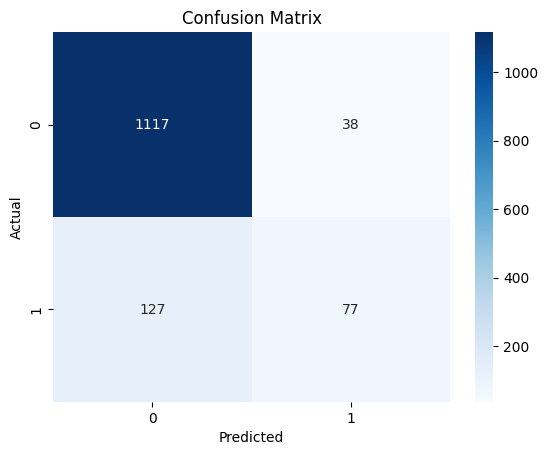

In [712]:
y_pred_rf = rf_model.predict(x_test)
print("Random Forest Test Accuracy:", accuracy_score(y_test, y_pred_rf))

print('\n')

y_pred_lm = logistic_model.predict(x_test)
print("Logistic Accuracy:", accuracy_score(y_test, y_pred_lm))
print("Logistic Precision:", precision_score(y_test, y_pred_lm))
print("Recall:", recall_score(y_test, y_pred_lm))
print("F1 Score:", f1_score(y_test, y_pred_lm))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lm))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lm))

cm = confusion_matrix(y_test, y_pred_lm)
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [713]:
y_prob_rf = rf_model.predict_proba(x_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("##### Random Forest #####")
print("Random Forest ROC-AUC:", roc_auc_rf)
print("Random Forest PR-AUC:", pr_auc_rf)
print("Random Forest F1 Score:", f1_score(y_test, y_pred_rf))

print("\n")
print("##### Logistic Regression #####")
y_prob_lm = logistic_model.predict_proba(x_test)[:, 1]

roc_auc_lm = roc_auc_score(y_test, y_prob_lm)
pr_auc_lm = average_precision_score(y_test, y_prob_lm)

print("Logistic Regression ROC-AUC:", roc_auc_lm)
print("Logistic Regression PR-AUC:", pr_auc_lm)
print("Logistic Regression F1 Score:", f1_score(y_test, y_pred_lm))


##### Random Forest #####
Random Forest ROC-AUC: 0.9042419998302351
Random Forest PR-AUC: 0.5782841560844143
Random Forest F1 Score: 0.48255813953488375


##### Logistic Regression #####
Logistic Regression ROC-AUC: 0.9141074611662846
Logistic Regression PR-AUC: 0.6289186301343057
Logistic Regression F1 Score: 0.4827586206896552


## **Neural Network**

In [714]:
np.random.seed(42)
tf.random.set_seed(42)

scaler = StandardScaler()
x_train_scaled = x_train
x_val_scaled = x_val
x_test_scaled = x_test
print(f"Train: {x_train.shape}, Test: {x_test.shape}")

early_stop = EarlyStopping(monitor='val_loss', mode = 'min', patience=8,
restore_best_weights=True)

def build_model(input_dims):
    model = keras.Sequential([
        layers.Input(shape=(input_dims.shape[1],)),

        layers.Dense(
            32,
            activation='relu',
            kernel_regularizer=keras.regularizers.l2(1e-4)
        ),
        layers.Dropout(0.3),

        layers.Dense(
            16,
            activation='relu',
            kernel_regularizer=keras.regularizers.l2(1e-4)
        ),
        layers.Dropout(0.2),

        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.AUC(curve='PR', name='pr_auc')
        ]
    )

    return model

neural_model = build_model(x_train)
history_nm = neural_model.fit(
    x_train_scaled,
    y_train,
    validation_data=(x_val_scaled, y_val),
    epochs=200,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop] )

Train: (24392, 1201), Test: (1359, 1201)
Epoch 1/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8584 - loss: 0.3644 - pr_auc: 0.3220 - roc_auc: 0.7633 - val_accuracy: 0.9000 - val_loss: 0.2648 - val_pr_auc: 0.7012 - val_roc_auc: 0.9136
Epoch 2/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8858 - loss: 0.2802 - pr_auc: 0.4800 - roc_auc: 0.8647 - val_accuracy: 0.9026 - val_loss: 0.2514 - val_pr_auc: 0.7145 - val_roc_auc: 0.9195
Epoch 3/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8898 - loss: 0.2714 - pr_auc: 0.5137 - roc_auc: 0.8758 - val_accuracy: 0.9026 - val_loss: 0.2466 - val_pr_auc: 0.7191 - val_roc_auc: 0.9200
Epoch 4/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8902 - loss: 0.2652 - pr_auc: 0.5216 - roc_auc: 0.8835 - val_accuracy: 0.9013 - val_loss: 0.2472 - val_pr_auc: 0.7257 - val_roc_auc: 0.9213
Epoch 5/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8895 - loss: 0.2607 - pr_auc: 0.5337 - roc_auc: 0.8882 - val_acc

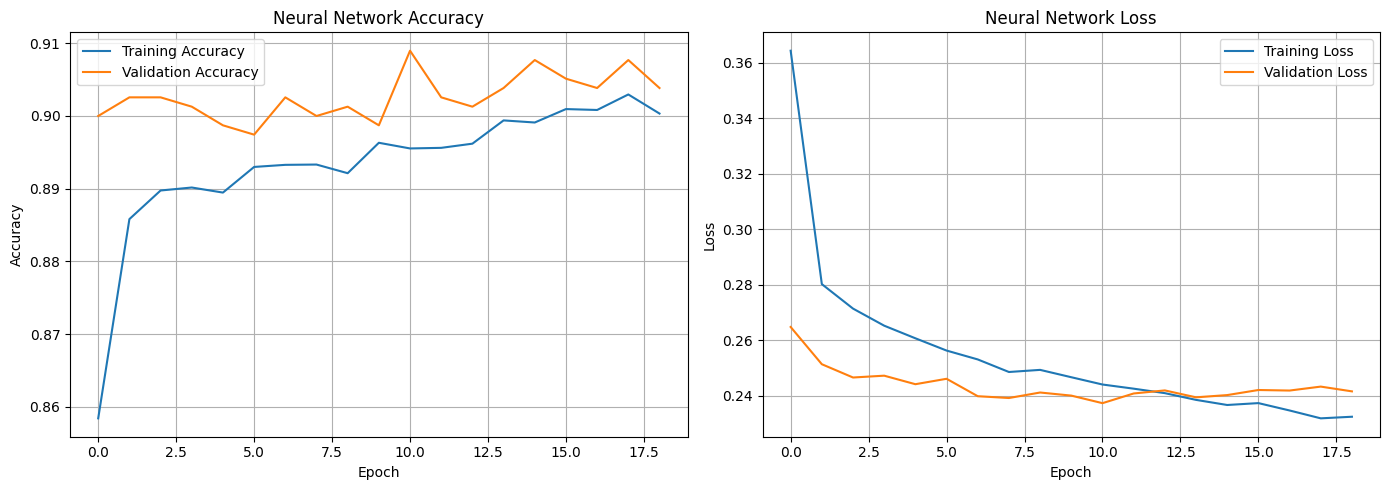

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
===== Neural Network Test Results =====
Accuracy:  0.8786
Precision: 0.6275
Recall:    0.4706
F1 Score:  0.5378
ROC-AUC:   0.9231
PR-AUC:    0.6443

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93      1155
           1       0.63      0.47      0.54       204

    accuracy                           0.88      1359
   macro avg       0.77      0.71      0.73      1359
weighted avg       0.87      0.88      0.87      1359



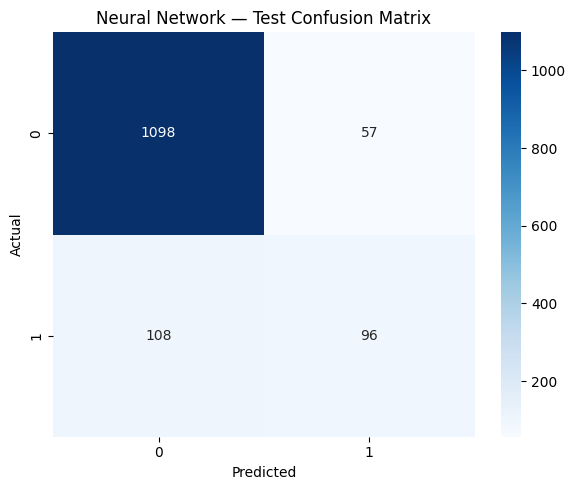

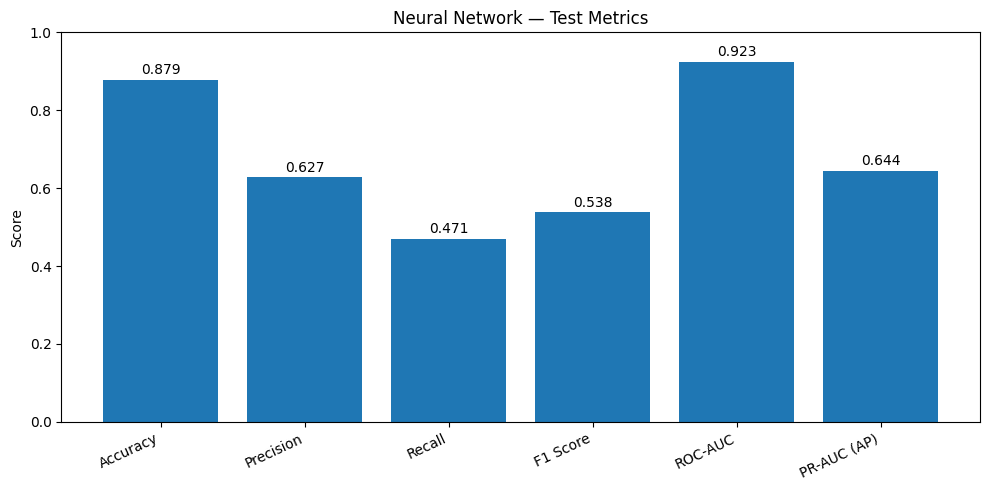

In [715]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_nm.history['accuracy'], label='Training Accuracy')
plt.plot(history_nm.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Neural Network Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_nm.history['loss'], label='Training Loss')
plt.plot(history_nm.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Neural Network Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

y_prob_nn = neural_model.predict(x_test_scaled).ravel()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_test, y_pred_nn)
precision = precision_score(y_test, y_pred_nn, zero_division=0)
recall = recall_score(y_test, y_pred_nn, zero_division=0)
f1 = f1_score(y_test, y_pred_nn, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob_nn)
pr_auc = average_precision_score(y_test, y_prob_nn)

print("===== Neural Network Test Results =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_nn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Neural Network — Test Confusion Matrix')
plt.tight_layout()
plt.show()

metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'ROC-AUC': roc_auc,
    'PR-AUC (AP)': pr_auc
}

plt.figure(figsize=(10, 5))
bars = plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)
plt.ylabel('Score')
plt.title('Neural Network — Test Metrics')
plt.xticks(rotation=25, ha='right')

for bar, score in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f'{score:.3f}',
        ha='center'
    )

plt.tight_layout()
plt.show()

# **Experiments**

In [716]:
cleaned_tables['races'].sort_values('raceId')

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1120,1140,2024,20,32,Mexico City Grand Prix,2024-10-27,20:00:00,https://en.wikipedia.org/wiki/2024_Mexico_City...,2024-10-25,18:30:00,2024-10-25,22:00:00,2024-10-26,17:30:00,2024-10-26,21:00:00,NaN,NaN
1121,1141,2024,21,18,São Paulo Grand Prix,2024-11-03,17:00:00,https://en.wikipedia.org/wiki/2024_S%C3%A3o_Pa...,2024-11-01,14:30:00,2024-11-01,18:30:00,NaN,NaN,2024-11-02,18:00:00,2024-11-02,14:00:00
1122,1142,2024,22,80,Las Vegas Grand Prix,2024-11-23,06:00:00,https://en.wikipedia.org/wiki/2024_Las_Vegas_G...,2024-11-21,02:30:00,2024-11-21,06:00:00,2024-11-22,02:30:00,2024-11-22,06:00:00,NaN,NaN
1123,1143,2024,23,78,Qatar Grand Prix,2024-12-01,17:00:00,https://en.wikipedia.org/wiki/2024_Qatar_Grand...,2024-11-29,13:30:00,2024-11-29,17:30:00,NaN,NaN,2024-11-30,17:00:00,2024-11-30,13:00:00


In [717]:
cleaned_tables['driver_standings'][cleaned_tables['driver_standings']['driverId'] == 3].sort_values(by='raceId')

,driverStandingsId,raceId,driverId,points,position,positionText,wins
7226,8252,1,3,3.0,6,6,0
7245,17656,2,3,3.5,7,7,0
7777,17716,3,3,3.5,11,11,0
7794,17756,4,3,3.5,11,11,0
7807,17776,5,3,4.5,10,10,0
...,...,...,...,...,...,...,...
31158,67942,964,3,313.0,1,1,9
31205,68038,965,3,331.0,1,1,9
31231,68062,966,3,349.0,1,1,9
31211,68108,967,3,367.0,1,1,9


In [718]:
temp_standings = cleaned_tables['driver_standings']
temp_standings = temp_standings[temp_standings['driverId'] == 1].merge(cleaned_tables['races'][['raceId', 'year', 'round']], on='raceId')
temp_standings = temp_standings[temp_standings['year'] >= 2023]
temp_standings.sort_values(['year', 'round'])

,driverStandingsId,raceId,driverId,points,position,positionText,wins,year,round
310,72010,1098,1,10.0,5,5,0,2023,1
311,71890,1099,1,20.0,5,5,0,2023,2
312,71910,1100,1,38.0,4,4,0,2023,3
313,71930,1101,1,48.0,4,4,0,2023,4
314,71950,1102,1,56.0,4,4,0,2023,5
315,71970,1104,1,69.0,4,4,0,2023,6
316,72030,1105,1,87.0,4,4,0,2023,7
317,72070,1106,1,102.0,4,4,0,2023,8
318,72110,1107,1,106.0,4,4,0,2023,9
319,72130,1108,1,121.0,4,4,0,2023,10


In [719]:
cleaned_tables['pit_stops'].info()
print(len(cleaned_tables['pit_stops']['raceId'].unique()))
len(cleaned_tables['races'])
print('testing')

<class 'pandas.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   raceId        11371 non-null  int64
 1   driverId      11371 non-null  int64
 2   stop          11371 non-null  int64
 3   lap           11371 non-null  int64
 4   time          11371 non-null  str  
 5   duration      11371 non-null  str  
 6   milliseconds  11371 non-null  int64
 7   stopId        11371 non-null  str  
dtypes: int64(5), str(3)
memory usage: 710.8 KB
285
testing


<class 'pandas.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   year                           26531 non-null  int64  
 1   time                           8290 non-null   str    
 2   round                          26531 non-null  int64  
 3   country                        26531 non-null  str    
 4   circuitRef                     26531 non-null  str    
 5   lng                            26531 non-null  float64
 6   lat                            26531 non-null  float64
 7   alt                            26531 non-null  int64  
 8   grid                           26531 non-null  int64  
 9   positionOrder                  26531 non-null  int64  
 10  q1                             26531 non-null  float64
 11  driverRef                      26531 non-null  str    
 12  nationality                    26531 non-null  str    
 1

,year,time,round,country,circuitRef,lng,lat,alt,grid,positionOrder,q1,driverRef,nationality,constructorRef,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,podium
0,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,1,1,85.211,button,British,brawn,0.0,0.0,3.0,0.0,29,1
1,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,2,2,85.006,barrichello,Brazilian,brawn,0.0,0.0,11.0,0.0,36,1
2,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,20,3,86.194,trulli,Italian,toyota,0.0,0.0,31.0,0.0,34,1
3,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,19,4,85.499,glock,German,toyota,0.0,0.0,25.0,0.0,27,0
4,2009,06:00:00,1,Australia,albert_park,144.968,-37.8497,10,10,5,86.026,alonso,Spanish,renault,0.0,0.0,61.0,2.0,27,0


Training: (24392, 20)
Validation: (780, 20)
Testing: (1359, 20)
Training Percentage of Data: 91.93773321774528
Validation Percentage of Data: 2.9399570313972334
Testing Percentage of Data: 5.122309750857487


,grid,round,year,lng,lat,alt,driver_points_before_race,driver_wins_before_race,driver_previous_season_points,driver_previous_season_wins,age,q1,country,circuitRef,constructorRef,nationality,driverRef
0,1,1,2009,144.968,-37.8497,10,0.0,0.0,3.0,0.0,29,85.211,Australia,albert_park,brawn,British,button
1,2,1,2009,144.968,-37.8497,10,0.0,0.0,11.0,0.0,36,85.006,Australia,albert_park,brawn,Brazilian,barrichello
2,20,1,2009,144.968,-37.8497,10,0.0,0.0,31.0,0.0,34,86.194,Australia,albert_park,toyota,Italian,trulli
3,19,1,2009,144.968,-37.8497,10,0.0,0.0,25.0,0.0,27,85.499,Australia,albert_park,toyota,German,glock
4,10,1,2009,144.968,-37.8497,10,0.0,0.0,61.0,2.0,27,86.026,Australia,albert_park,renault,Spanish,alonso


0    1
1    1
2    1
3    0
4    0
Name: podium, dtype: int64

Epoch 1/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8798 - loss: 0.2904 - pr_auc: 0.4356 - roc_auc: 0.8465 - val_accuracy: 0.9000 - val_loss: 0.2546 - val_pr_auc: 0.7075 - val_roc_auc: 0.9146
Epoch 2/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8875 - loss: 0.2564 - pr_auc: 0.5163 - roc_auc: 0.8905 - val_accuracy: 0.8987 - val_loss: 0.2472 - val_pr_auc: 0.7136 - val_roc_auc: 0.9189
Epoch 3/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8893 - loss: 0.2517 - pr_auc: 0.5336 - roc_auc: 0.8966 - val_accuracy: 0.9000 - val_loss: 0.2434 - val_pr_auc: 0.7245 - val_roc_auc: 0.9220
Epoch 4/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8916 - loss: 0.2469 - pr_auc: 0.5489 - roc_auc: 0.9020 - val_accuracy: 0.8974 - val_loss: 0.2467 - val_pr_auc: 0.7230 - val_roc_auc: 0.9216
Epoch 5/200
763/763 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8920 - loss: 0.2455 - pr_auc: 0.5485 - roc_auc: 0.9039 - val_accuracy: 0.8987 - val_loss: 0.2457 - val_pr

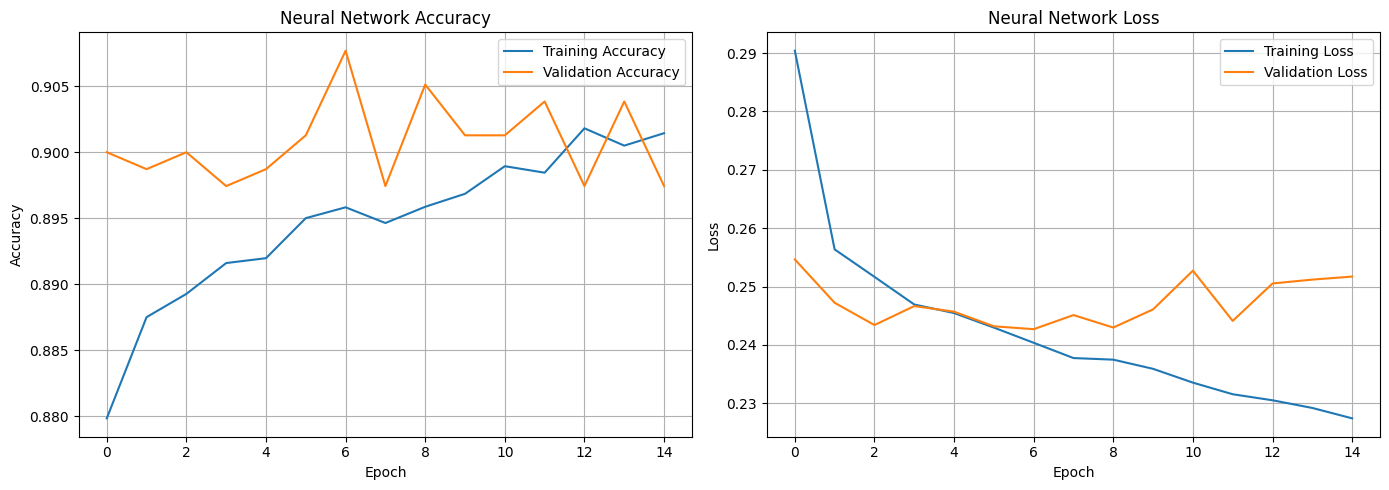

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
===== Neural Network Test Results =====
Accuracy:  0.8808
Precision: 0.6207
Recall:    0.5294
F1 Score:  0.5714
ROC-AUC:   0.9247
PR-AUC:    0.6428

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93      1155
           1       0.62      0.53      0.57       204

    accuracy                           0.88      1359
   macro avg       0.77      0.74      0.75      1359
weighted avg       0.87      0.88      0.88      1359



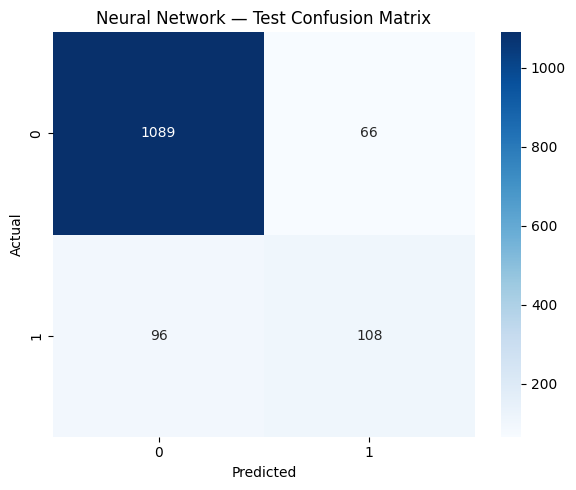

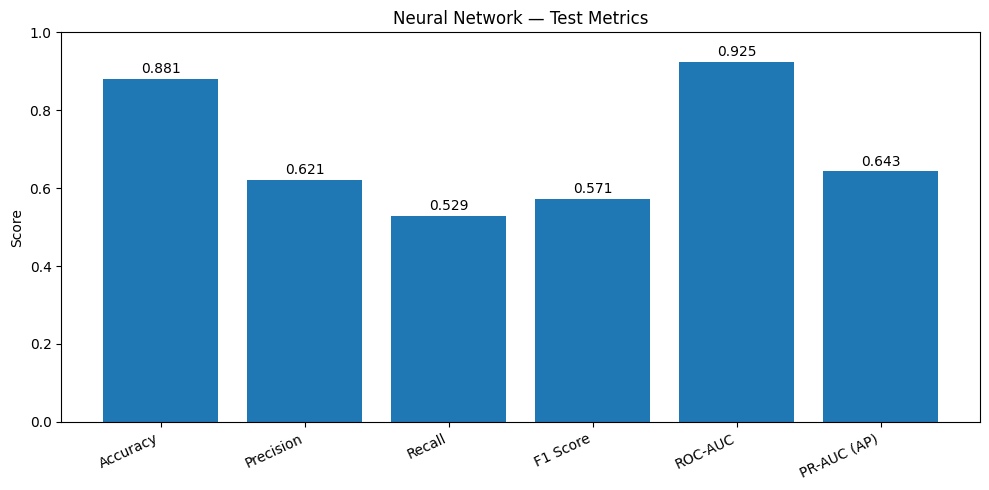

In [ ]:
dropped_noncompliant_columns_modeling_data['podium'] = dropped_noncompliant_columns_modeling_data['positionOrder'].isin([1, 2, 3]).astype(int)
dropped_noncompliant_columns_modeling_data.info()
display(dropped_noncompliant_columns_modeling_data.head())

experiment_1_data = dropped_noncompliant_columns_modeling_data.copy()
training_exp1, validation_exp1, testing_exp1 = create_modeling_split(experiment_1_data)

numeric_features = ['grid', 'round', 'year', 'lng', 'lat', 'alt', 
                    'driver_points_before_race', 'driver_wins_before_race', 'driver_previous_season_points', 'driver_previous_season_wins', 
                    'age', 'q1']

categorical_features = ['country', 'circuitRef', 'constructorRef', 'nationality', 'driverRef']

features = numeric_features + categorical_features

x_train_exp1 = training_exp1[features]
y_train_exp1 = training_exp1['podium']

x_val_exp1 = validation_exp1[features]
y_val_exp1 = validation_exp1['podium']

x_test_exp1 = testing_exp1[features]
y_test_exp1 = testing_exp1['podium']

display(x_train_exp1.head())
display(y_train_exp1.head())

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

x_train_exp1 = preprocessor.fit_transform(x_train_exp1)
x_val_exp1 = preprocessor.transform(x_val_exp1)
x_test_exp1 = preprocessor.transform(x_test_exp1)

neural_model_exp1 = build_model(x_train_exp1)
history_nm_exp1 = neural_model_exp1.fit(
    x_train_exp1,
    y_train_exp1,
    validation_data=(x_val_exp1, y_val_exp1),
    epochs=200,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop] )

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_nm_exp1.history['accuracy'], label='Training Accuracy')
plt.plot(history_nm_exp1.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Neural Network Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_nm_exp1.history['loss'], label='Training Loss')
plt.plot(history_nm_exp1.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Neural Network Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

y_prob_nn = neural_model_exp1.predict(x_test_exp1).ravel()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_test_exp1, y_pred_nn)
precision = precision_score(y_test_exp1, y_pred_nn, zero_division=0)
recall = recall_score(y_test_exp1, y_pred_nn, zero_division=0)
f1 = f1_score(y_test_exp1, y_pred_nn, zero_division=0)
roc_auc = roc_auc_score(y_test_exp1, y_prob_nn)
pr_auc = average_precision_score(y_test_exp1, y_prob_nn)

print("===== Neural Network Test Results =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_exp1, y_pred_nn, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test_exp1, y_pred_nn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Neural Network — Test Confusion Matrix')
plt.tight_layout()
plt.show()

metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'ROC-AUC': roc_auc,
    'PR-AUC (AP)': pr_auc
}

plt.figure(figsize=(10, 5))
bars = plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)
plt.ylabel('Score')
plt.title('Neural Network — Test Metrics')
plt.xticks(rotation=25, ha='right')

for bar, score in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f'{score:.3f}',
        ha='center'
    )

plt.tight_layout()
plt.show()

In [ ]:
# def add_pit_stop_features(modeling_data, results, pit_stops, races):
#     """
#     Add pre-race pit-stop history features.

#     Current-season features use eligible races before the target race.
#     Previous-season features use eligible races in the previous calendar year.

#     A race is considered covered when pit_stops contains records for it.
#     Missing driver-level stop counts within covered races are treated as zero.
#     Uncovered races are excluded rather than treated as zero-stop races.
#     """

#     race_info = races[['raceId', 'year', 'round']].copy()

#     # Identify races for which the pit-stop table contains records.
#     covered_races = pit_stops['raceId'].dropna().unique()

#     # Convert stop duration to numeric seconds where possible.
#     stops = pit_stops[['raceId', 'driverId', 'duration']].copy()
#     stops['duration_seconds'] = pd.to_numeric(
#         stops['duration'], errors='coerce'
#     )

#     # Summarize each driver's stops within each race.
#     race_stop_stats = (
#         stops.groupby(['raceId', 'driverId'], as_index=False)
#         .agg(
#             stops_in_race=('raceId', 'size'),
#             mean_stop_duration=('duration_seconds', 'mean')
#         )
#     )

#     # Driver race participation, restricted to covered races.
#     participation = (
#         results[['raceId', 'driverId']]
#         .drop_duplicates()
#         .merge(race_info, on='raceId', how='left', validate='many_to_one')
#     )

#     participation = participation[
#         participation['raceId'].isin(covered_races)
#     ].copy()

#     # Missing driver-level records in a covered race are treated as zero stops.
#     participation = participation.merge(
#         race_stop_stats,
#         on=['raceId', 'driverId'],
#         how='left',
#         validate='one_to_one'
#     )

#     participation['stops_in_race'] = (
#         participation['stops_in_race'].fillna(0)
#     )

#     # Preserve target row order.
#     data = modeling_data.copy().reset_index(drop=True)
#     data['_row_id'] = range(len(data))

#     # Build all earlier same-season driver-race observations.
#     current_candidates = data[
#         ['_row_id', 'driverId', 'year', 'round']
#     ].merge(
#         participation,
#         on=['driverId', 'year'],
#         how='left',
#         suffixes=('', '_history')
#     )

#     current_candidates = current_candidates[
#         (current_candidates['round_history'] < current_candidates['round'])
#         & current_candidates['raceId'].notna()
#     ]

#     current_features = (
#         current_candidates.groupby('_row_id')
#         .agg(
#             avg_stop_duration_before_race=('mean_stop_duration', 'mean'),
#             avg_stops_per_race_before_race=('stops_in_race', 'mean')
#         )
#         .reset_index()
#     )

#     data = data.merge(
#         current_features,
#         on='_row_id',
#         how='left',
#         validate='one_to_one',
#         sort=False
#     )

#     # Aggregate each driver's previous-season history.
#     previous_features = (
#         participation
#         .groupby(['driverId', 'year'])
#         .agg(
#             avg_stop_duration_previous_season=('mean_stop_duration', 'mean'),
#             avg_stops_per_race_previous_season=('stops_in_race', 'mean')
#         )
#         .reset_index()
#         .rename(columns={'year': 'previous_season'})
#     )

#     data['previous_season'] = data['year'] - 1

#     data = data.merge(
#         previous_features,
#         on=['driverId', 'previous_season'],
#         how='left',
#         validate='many_to_one',
#         sort=False
#     )

#     return data.drop(columns=['_row_id', 'previous_season'])

In [ ]:
# modeling_data = add_pit_stop_features(
#     modeling_data=modeling_data,
#     results=cleaned_tables['results'],
#     pit_stops=cleaned_tables['pit_stops'],
#     races=cleaned_tables['races']
# )

In [ ]:
# q1_col = 'q1'  # Replace with the actual column name

# modeling_data['q1_missing'] = modeling_data[q1_col].isna()

# # Missingness by season
# modeling_data.groupby('year')['q1_missing'].agg(
#     missing_count='sum',
#     total='size',
#     missing_rate='mean'
# ).tail(20)

In [ ]:
# missing_pct = (
#     modeling_data.groupby('year')[q1_col]
#     .apply(lambda s: s.isna().mean() * 100)
# )

# plt.figure(figsize=(12, 5))
# plt.plot(missing_pct.index, missing_pct.values, marker='o')
# plt.xlabel('Year')
# plt.ylabel('Missing Q1 times (%)')
# plt.title('Percentage of Missing Q1 Times by Year')
# plt.xticks(sorted(modeling_data['year'].dropna().unique()), rotation=45)
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

In [ ]:
# print(modeling_data['year'].min())
# print(cleaned_tables['races']['year'].min())

In [ ]:
# # Work at race level to avoid counting the same race once per driver
# race_times = (
#     modeling_data[['raceId', 'year', 'time']]
#     .drop_duplicates(subset='raceId')
#     .copy()
# )

# # Convert HH:MM:SS strings to seconds after midnight
# race_times['start_seconds'] = (
#     pd.to_timedelta(race_times['time'], errors='coerce')
#     .dt.total_seconds()
# )

# # Keep only valid clock times
# valid_time = race_times['start_seconds'].between(0, 86400, inclusive='left')
# race_times.loc[~valid_time, 'start_seconds'] = float('nan')

# race_times['start_hour'] = race_times['start_seconds'] / 3600

# # Calculate missing percentage by year
# missing_by_year = (
#     race_times.groupby('year')['start_seconds']
#     .apply(lambda s: s.isna().mean() * 100)
# )

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# # Distribution of known start times
# axes[0].hist(
#     race_times['start_hour'].dropna(),
#     bins=24,
#     edgecolor='black'
# )
# axes[0].set(
#     title='Distribution of Recorded Race Start Times',
#     xlabel='Hour of day',
#     ylabel='Number of races',
#     xlim=(0, 24)
# )
# axes[0].set_xticks(range(0, 25, 2))
# axes[0].grid(axis='y', alpha=0.3)

# # Missing percentage by year
# axes[1].plot(
#     missing_by_year.index,
#     missing_by_year.values,
#     marker='o',
#     markersize=3
# )
# axes[1].set(
#     title='Missing Race Start Times by Year',
#     xlabel='Year',
#     ylabel='Missing times (%)',
#     ylim=(0, 105)
# )
# axes[1].grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()

In [ ]:
# cleaned_tables['pit_stops'].merge(cleaned_tables['races'], on= 'raceId')['year'].min()

In [ ]:
# print(modeling_data['position'].unique())
# print(cleaned_tables['qualifying']['position'].unique())
# print(qualifying['position'].unique())
# modeling_data['position'] = modeling_data['position'].astype('Int64')
# print(modeling_data['position'].unique())